# Data Ingestion and Preprocessing

### Import Colab setup utilities

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import shutil
import subprocess
import importlib.util
import zipfile
import urllib.request
import uuid
from datetime import datetime, timezone


### Detect the Colab environment

In [2]:
try:
    IS_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IS_COLAB = False
print('Runtime:', 'Google Colab' if IS_COLAB else 'Local Jupyter')


Runtime: Local Jupyter


### Configure Colab paths

In [3]:
COLAB_MOUNT_DRIVE = False # @param {type:"boolean"}
COLAB_BASE_DIR = Path(os.environ.get('COLAB_BASE_DIR', Path.cwd()))
COLAB_WORK_DIR = str(COLAB_BASE_DIR / 'bearing_rul' / 'handover_notebook_only')
COLAB_BUNDLE_ZIP = str(COLAB_BASE_DIR / 'handover_notebook_only.zip')
COLAB_RAW_SOURCE = 'download' # @param ["download", "drive_zip", "existing"]
COLAB_RAW_ROOT = str(COLAB_BASE_DIR / 'datasets' / 'pronostia' / 'ieee-phm-2012-data-challenge-dataset-master')
COLAB_OUTPUT_BASE = str(COLAB_BASE_DIR / 'bearing_rul_outputs')
COLAB_DRIVE_ROOT = COLAB_BASE_DIR / 'drive'
COLAB_DRIVE_ARCHIVE = str(COLAB_DRIVE_ROOT / 'MyDrive' / 'Bearing_RUL' / 'phm2012-master.zip')
COLAB_DOWNLOAD_ARCHIVE = str(COLAB_BASE_DIR / 'datasets' / 'pronostia' / 'phm2012-master.zip')


### Mount Google Drive when enabled

In [4]:
if IS_COLAB and (COLAB_MOUNT_DRIVE or COLAB_RAW_SOURCE=='drive_zip'):
    from google.colab import drive
    drive.mount(str(COLAB_DRIVE_ROOT))
else:
    print('Không mount Drive; dùng filesystem hiện tại.')


Không mount Drive; dùng filesystem hiện tại.


### Prepare the Colab notebook directory

In [5]:
if IS_COLAB:
    Path(COLAB_WORK_DIR).mkdir(parents=True,exist_ok=True)
    os.chdir(COLAB_WORK_DIR)
print('Working directory:',Path.cwd())


Working directory: <project_root>


### Receive the notebook bundle on Colab

In [6]:
required_bundle_files = ['data_process.ipynb','data_pipeline_scripts.ipynb','pronostia_config.yaml','test_ground_truth.csv','requirements.txt','README.md']
if IS_COLAB and not all(Path(name).is_file() for name in required_bundle_files):
    bundle_path = Path(COLAB_BUNDLE_ZIP)
    if not bundle_path.is_file():
        from google.colab import files
        print('Chọn handover_notebook_only.zip, KHÔNG chọn raw ZIP ở bước này.')
        uploaded = files.upload()
        candidates = [name for name in uploaded if name.lower().endswith('.zip')]
        assert len(candidates)==1, 'Cần đúng một ZIP bộ notebook'
        bundle_path = Path(candidates[0])
        bundle_path.write_bytes(uploaded[candidates[0]])
else:
    bundle_path = None


### Extract the required notebook files

In [7]:
if IS_COLAB and bundle_path is not None:
    with zipfile.ZipFile(bundle_path) as bundle:
        for filename in required_bundle_files:
            candidates=[name for name in bundle.namelist() if name in (filename,'handover_notebook_only/'+filename)]
            assert len(candidates)==1, f'Thiếu/trùng file trong ZIP: {filename}'
            Path(filename).write_bytes(bundle.read(candidates[0]))
    print('Đã nhận đầy đủ notebook/config/dependencies. Bỏ qua reports cũ trong ZIP.')


### Install dependencies on Colab

In [8]:
if IS_COLAB:
    subprocess.check_call([sys.executable,'-m','pip','install','--quiet','-r','requirements.txt'])
else:
    print('Local: dùng môi trường đã cài; pip install -r requirements.txt khi cần.')


Local: dùng môi trường đã cài; pip install -r requirements.txt khi cần.


### Import data processing libraries

In [9]:
from pathlib import Path
from collections import Counter, defaultdict, OrderedDict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from io import StringIO
import csv
import hashlib
import json
import os
import platform
import re
import shutil
import sys
import tempfile
import time
import unittest
import copy
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import yaml
import torch
from torch.utils.data import Dataset, DataLoader
from scipy.signal import butter, sosfiltfilt, resample_poly, welch, spectrogram, hilbert, spectrogram, hilbert, spectrogram, hilbert, spectrogram, hilbert
from scipy.stats import kurtosis as scipy_kurtosis
from scipy.stats import kurtosis as scipy_kurtosis
from scipy.stats import kurtosis as scipy_kurtosis
from scipy.stats import kurtosis as scipy_kurtosis
import matplotlib
import matplotlib.pyplot as plt
import psutil


### Load the preprocessing configuration

In [10]:
def find_bundle_root(start=None):
    override = os.environ.get('PRONOSTIA_PROJECT_ROOT')
    start = Path(start or Path.cwd()).resolve()
    candidates = ([Path(override).expanduser().resolve()] if override else []) + [start, *start.parents]
    for base in candidates:
        for candidate in (base, base / 'handover_notebook_only', base / 'customer_handover'):
            if (candidate / 'pronostia_config.yaml').is_file() and (candidate / 'data_process.ipynb').is_file():
                return candidate.resolve()
    raise FileNotFoundError('Không tìm thấy bộ notebook. Hãy mở Jupyter từ thư mục bàn giao hoặc đặt PRONOSTIA_PROJECT_ROOT.')

PROJECT_ROOT = find_bundle_root()
CONFIG = yaml.safe_load((PROJECT_ROOT / 'pronostia_config.yaml').read_text(encoding='utf-8'))
assert CONFIG['max_files'] is None
assert set(CONFIG['test_rul_at_cut_seconds']) == {f'Bearing{c}_{i}' for c in (1,2) for i in range(3,8)} | {'Bearing3_3'}


### Define the data contract

In [11]:
VERSION = 'pronostia-notebook-v2'
LEARNING = [f'Bearing{c}_{b}' for c in (1,2,3) for b in (1,2)]
TEST = [f'Bearing{c}_{b}' for c in (1,2) for b in range(3,8)] + ['Bearing3_3']
CONDITIONS = {1:(1800,4000), 2:(1650,4200), 3:(1500,5000)}
FEATURE_NAMES = ['current','mean','std','min','max','slope_per_s','time_since_valid_s']


### Define natural_key

In [12]:
def natural_key(value):
    return [int(p) if p.isdigit() else p.lower() for p in re.split('(\\d+)', str(value))]


### Define file_index

In [13]:
def file_index(path):
    return int(re.findall('\\d+', path.stem)[-1])


### Define fingerprint

In [14]:
def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()


### Define write_json

In [15]:
def write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')


### Define Parsed

In [16]:
@dataclass
class Parsed:
    data: np.ndarray
    timestamps: np.ndarray
    schema: dict


### Define unwrap_clock

In [17]:
def unwrap_clock(times):
    """Unwrap midnight only; preserve small backward jumps as quality failures."""
    times = np.asarray(times, dtype=np.float64)
    if not len(times):
        return times.copy()
    offsets = np.r_[0, np.cumsum(np.diff(times) < -43200)] * 86400
    return times + offsets


### Define repair_acquisition_clock

In [18]:
def repair_acquisition_clock(indices, timestamps, period, tolerance=0.001):
    """Repair ONLY bounded outliers when both neighbors verify the same acquisition grid."""
    timestamps = np.asarray(timestamps, dtype=np.float64)
    indices = np.asarray(indices)
    grid = timestamps[0] + (indices - indices[0]) * period
    bad = np.abs(timestamps - grid) > tolerance
    repairs = []
    if not bad.any():
        return (timestamps.copy(), repairs)
    if bad.mean() > 0.01:
        raise ValueError('clock outliers exceed 1%; cannot justify nominal-grid repair')
    result = timestamps.copy()
    bad_indices = np.flatnonzero(bad)
    groups = np.split(bad_indices, np.where(np.diff(bad_indices) > 1)[0] + 1)
    for group in groups:
        left, right = (int(group[0] - 1), int(group[-1] + 1))
        if left < 0 or right >= len(timestamps):
            raise ValueError('unbounded clock outlier; cannot repair endpoint')
        if abs(timestamps[right] - timestamps[left] - (indices[right] - indices[left]) * period) > tolerance:
            raise ValueError('neighbor clock span does not verify nominal acquisition interval')
        for j in group:
            corrected = timestamps[left] + (indices[j] - indices[left]) * period
            repairs.append({'acquisition_index': int(indices[j]), 'raw_timestamp': float(timestamps[j]), 'canonical_timestamp': float(corrected), 'reason': 'clock outlier bracketed by verified nominal acquisition interval'})
            result[j] = corrected
    return (result, repairs)


### Define inspect_file

In [19]:
def inspect_file(path, root, subset, bearing, modality, config):
    stat = path.stat()
    content = path.read_bytes()
    record = {'path': path.relative_to(root).as_posix(), 'subset': subset, 'bearing_id': bearing, 'modality': modality, 'size_bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns, 'sha256': hashlib.sha256(content).hexdigest(), 'data_status': 'ok'}
    try:
        record['acquisition_index'] = file_index(path)
        parsed = parse_csv(path, modality, config['expected_acc_samples'], config['temperature']['fraction_scale'], raw_bytes=content)
        record.update(parsed.schema)
        record.update({'first_timestamp': float(parsed.timestamps[0]), 'last_timestamp': float(parsed.timestamps[-1])})
    except (ValueError, OSError, UnicodeError) as exc:
        record.update({'data_status': 'quarantined', 'reason': str(exc), 'rows': None})
    return record


### Define assert_disjoint

In [20]:
def assert_disjoint(split):
    sets = [set(split.get(k, [])) for k in ('train', 'validation', 'test')]
    if any((sets[i] & sets[j] for i in range(3) for j in range(i + 1, 3))):
        raise ValueError('bearing overlap across splits')
    if set(split.get('train', [])) - set(LEARNING):
        raise ValueError('training must use Learning_set bearings only')
    if set(split.get('validation', [])) - set(LEARNING):
        raise ValueError('validation must use Learning_set bearings only')


### Define protocols

In [21]:
def protocols(seed=42):
    folds = [{'fold': i, 'train': [b for b in LEARNING if b != held], 'validation': [held], 'test': []} for i, held in enumerate(LEARNING)]
    official = {'fold': 'official', 'train': LEARNING.copy(), 'validation': [], 'test': TEST.copy()}
    for split in folds + [official]:
        assert_disjoint(split)
    return {'seed': seed, 'development_cv': folds, 'official_benchmark': official}


### Define transform_vibration

In [22]:
def transform_vibration(data, config):
    x = np.asarray(data, dtype=np.float64)
    if x.shape != (2, 2560) or not np.isfinite(x).all():
        raise ValueError('vibration must be finite [2,2560]')
    x = x - x.mean(axis=-1, keepdims=True)
    mode = config['mode']
    fs = config['sampling_rate_hz']
    if fs != 25600:
        raise ValueError('PRONOSTIA source sampling rate must be 25600 Hz')
    if mode in ('bandpass_full', 'resample_1024'):
        low, high = config['bandpass_hz']
        if not 0 < low < high < fs / 2:
            raise ValueError('invalid cutoff relative to Nyquist')
        if mode == 'resample_1024':
            x = resample_poly(x, 2, 5, axis=-1)
            fs = config['effective_sampling_rate_hz']
            high = min(high, fs / 2 * 0.99)
        x = sosfiltfilt(butter(config['filter_order'], [low, high], fs=fs, btype='bandpass', output='sos'), x, axis=-1)
    elif mode != 'raw_demean':
        raise ValueError(f'unknown vibration mode: {mode}')
    if not np.isfinite(x).all():
        raise ValueError('non-finite vibration after preprocessing')
    return x.astype(np.float32)


### Define bearing baseline features


In [23]:
def bearing_characteristic_frequencies(condition_id, config):
    feature_config = config['handcrafted_features']
    geometry = feature_config['bearing_geometry']
    rpm = float(feature_config['condition_speed_rpm'][condition_id])
    shaft_frequency = rpm / 60.0
    rolling_elements = float(geometry['rolling_element_count'])
    ball_diameter = float(geometry['rolling_element_diameter_mm'])
    pitch_diameter = float(geometry['pitch_diameter_mm'])
    contact_angle = np.deg2rad(float(geometry['contact_angle_deg']))
    ratio = ball_diameter / pitch_diameter * np.cos(contact_angle)
    return {
        'shaft': shaft_frequency,
        'bpfo': rolling_elements / 2.0 * shaft_frequency * (1.0 - ratio),
        'bpfi': rolling_elements / 2.0 * shaft_frequency * (1.0 + ratio),
        'bsf': pitch_diameter / (2.0 * ball_diameter) * shaft_frequency * (1.0 - ratio ** 2),
    }


def handcrafted_feature_names(config):
    channels = config['handcrafted_features']['channel_names']
    harmonics = config['handcrafted_features']['harmonics']
    names = []
    for channel in channels:
        names.extend(f'{channel}_{name}' for name in ('rms', 'kurtosis', 'crest_factor', 'skewness', 'peak_to_peak'))
        names.extend(f'{channel}_{name}' for name in ('spectral_kurtosis_mean', 'spectral_kurtosis_max', 'spectral_kurtosis_peak_hz'))
        names.extend(f'{channel}_{fault}_h{harmonic}_relative_bandpower' for fault in ('bpfo', 'bpfi', 'bsf') for harmonic in harmonics)
    names.extend(('temperature_mean_c', 'temperature_gradient_c_per_s', 'temperature_rms_c'))
    return names


def _spectral_kurtosis_summary(signal, sampling_rate, segment_length):
    segment_length = min(int(segment_length), signal.size)
    frequencies, _, power = spectrogram(signal, fs=sampling_rate, nperseg=segment_length,
                                         noverlap=segment_length // 2, mode='psd')
    centered = power - power.mean(axis=-1, keepdims=True)
    variance = np.mean(centered ** 2, axis=-1)
    values = np.divide(np.mean(centered ** 4, axis=-1), variance ** 2,
                       out=np.zeros_like(variance), where=variance > 0)
    valid = frequencies > 0
    if not valid.any():
        return (0.0, 0.0, 0.0)
    selected_values = values[valid]
    selected_frequencies = frequencies[valid]
    peak = int(np.argmax(selected_values))
    return (float(selected_values.mean()), float(selected_values[peak]), float(selected_frequencies[peak]))


def _relative_envelope_bandpowers(signal, sampling_rate, targets, half_width_hz):
    envelope = np.abs(hilbert(signal))
    envelope = envelope - envelope.mean()
    spectrum = np.abs(np.fft.rfft(envelope)) ** 2
    frequencies = np.fft.rfftfreq(envelope.size, d=1.0 / sampling_rate)
    spectrum[0] = 0.0
    total = float(spectrum.sum())
    values = []
    for target in targets:
        selected = np.abs(frequencies - target) <= half_width_hz
        if not selected.any():
            selected[np.argmin(np.abs(frequencies - target))] = True
        values.append(float(spectrum[selected].sum() / total) if total > 0 else 0.0)
    return values


def extract_handcrafted_features(vibration, temperature, temperature_mask, condition_id, config):
    vibration = np.asarray(vibration, dtype=np.float64)
    temperature = np.asarray(temperature, dtype=np.float64)
    temperature_mask = np.asarray(temperature_mask, dtype=bool)
    if vibration.ndim != 3 or vibration.shape[1] != 2:
        raise ValueError('vibration must have shape [acquisition,2,samples]')
    if temperature.shape != temperature_mask.shape or temperature.shape[0] != vibration.shape[0]:
        raise ValueError('temperature and mask must align with vibration acquisitions')
    feature_config = config['handcrafted_features']
    sampling_rate = float(config['vibration']['effective_sampling_rate_hz'] if config['vibration']['mode'] == 'resample_1024'
                          else config['vibration']['sampling_rate_hz'])
    fault_frequencies = bearing_characteristic_frequencies(str(condition_id), config)
    harmonics = [int(value) for value in feature_config['harmonics']]
    targets = [fault_frequencies[fault] * harmonic for fault in ('bpfo', 'bpfi', 'bsf') for harmonic in harmonics]
    rows = []
    for acquisition, temp_history, temp_missing in zip(vibration, temperature, temperature_mask):
        row = []
        for signal in acquisition:
            centered = signal - signal.mean()
            rms = float(np.sqrt(np.mean(signal ** 2)))
            standard_deviation = float(np.sqrt(np.mean(centered ** 2)))
            if standard_deviation > 0:
                skewness = float(np.mean(centered ** 3) / standard_deviation ** 3)
                kurtosis = float(np.mean(centered ** 4) / standard_deviation ** 4)
            else:
                skewness, kurtosis = 0.0, 0.0
            crest_factor = float(np.max(np.abs(signal)) / rms) if rms > 0 else 0.0
            row.extend((rms, kurtosis, crest_factor, skewness, float(np.ptp(signal))))
            row.extend(_spectral_kurtosis_summary(signal, sampling_rate, feature_config['spectral_kurtosis_segment_length']))
            row.extend(_relative_envelope_bandpowers(signal, sampling_rate, targets, feature_config['fault_band_half_width_hz']))
        flat_temperature = temp_history.reshape(-1)
        valid_temperature = ~temp_missing.reshape(-1)
        values = flat_temperature[valid_temperature]
        if values.size:
            time_axis = np.flatnonzero(valid_temperature).astype(np.float64) * float(feature_config['temperature_history_step_s'])
            gradient = float(np.polyfit(time_axis, values, 1)[0]) if values.size > 1 else 0.0
            row.extend((float(values.mean()), gradient, float(np.sqrt(np.mean(values ** 2)))))
        else:
            row.extend((np.nan, np.nan, np.nan))
        rows.append(row)
    result = np.asarray(rows, dtype=np.float32)
    if result.shape[1] != len(handcrafted_feature_names(config)):
        raise ValueError('handcrafted feature schema mismatch')
    return result


def add_handcrafted_features(arrays, config):
    result = dict(arrays)
    condition_id = str(np.asarray(result['condition_id']).item())
    result['handcrafted_features'] = extract_handcrafted_features(
        result['vibration'], result['temperature'], result['temperature_mask'], condition_id, config)
    result['handcrafted_feature_names'] = np.asarray(handcrafted_feature_names(config))
    return result


def handcrafted_feature_schema(config):
    feature_config = config['handcrafted_features']
    return {
        'feature_names': handcrafted_feature_names(config),
        'bearing_characteristic_frequencies_hz': {
            condition: bearing_characteristic_frequencies(condition, config)
            for condition in feature_config['condition_speed_rpm']
        },
        'harmonics': feature_config['harmonics'],
        'fault_band_half_width_hz': feature_config['fault_band_half_width_hz'],
        'spectral_kurtosis_segment_length': feature_config['spectral_kurtosis_segment_length'],
        'bearing_geometry': feature_config['bearing_geometry'],
        'definitions': {
            'kurtosis': 'Pearson fourth standardized moment',
            'spectral_kurtosis': 'Pearson kurtosis of spectrogram power across time frames, summarized by mean, maximum, and peak frequency',
            'fault_features': 'relative Hilbert-envelope spectrum bandpower around BPFO, BPFI, BSF, and configured harmonics',
            'temperature_gradient': 'least-squares slope over valid causal temperature-history timestamps',
        },
        'normalization': 'training-bearing mean and standard deviation per fold; missing temperature features map to zero after scaling',
    }


### Define causal_temperature

In [24]:
def causal_temperature(times, values, queries, config):
    times, values, queries = map(np.asarray, (times, values, queries))
    if len(times) and ((np.diff(times) <= 0).any() or not np.isfinite(values).all()):
        raise ValueError('temperature series must be finite and strictly increasing')
    history = config['history_horizon_s']
    gap = config['max_alignment_gap_s']
    representation = config['representation']
    shape = (len(queries), 7) if representation == 'temp_features' else (len(queries), 1, 64)
    if representation not in ('temp_features', 'temp_history_64'):
        raise ValueError('unsupported temperature representation')
    out = np.zeros(shape, np.float32)
    missing = np.ones(shape, bool)
    matched = np.full(len(queries), np.nan)
    delta = np.full(len(queries), np.nan)
    for i, q in enumerate(queries):
        end = np.searchsorted(times, q, side='right')
        if not end:
            continue
        j = end - 1
        matched[i], delta[i] = (times[j], q - times[j])
        start = np.searchsorted(times, q - history, side='left')
        t, v = (times[start:end], values[start:end])
        if representation == 'temp_features':
            out[i, -1], missing[i, -1] = (delta[i], False)
            if delta[i] > gap or not len(t):
                continue
            slope = 0.0 if len(t) < 2 else float(np.polyfit(t - t[0], v, 1)[0])
            out[i] = [values[j], v.mean(), v.std(), v.min(), v.max(), slope, delta[i]]
            missing[i] = False
        else:
            grid = np.linspace(q - history, q, 64)
            pos = np.searchsorted(times[:end], grid, side='right') - 1
            good = pos >= 0
            good[good] &= grid[good] - times[pos[good]] <= gap
            out[i, 0, good] = values[pos[good]]
            missing[i, 0, good] = False
    return (out, missing, matched, delta)


### Define load_temperature

In [25]:
def load_temperature(root, records, acquisition_start, config):
    times, values, paths = ([], [], [])
    for record in records:
        if record['modality'] != 'temp' or record['data_status'] == 'quarantined':
            continue
        p = parse_csv(root / record['path'], 'temp', temp_fraction_scale=config['fraction_scale'])
        times.extend(p.timestamps.tolist())
        values.extend(p.data[0].tolist())
        paths.extend([record['path']] * len(p.timestamps))
    if not times:
        return (np.array([]), np.array([]), np.array([], dtype=str), {'samples': 0, 'removed': 0})
    times, values, paths = (unwrap_clock(np.asarray(times)), np.asarray(values), np.asarray(paths))
    if times[0] < acquisition_start - 43200:
        times += 86400
    elif times[0] > acquisition_start + 43200:
        times -= 86400
    if (np.diff(times) <= 0).any():
        raise ValueError('non-increasing temperature stream across files')
    bounds = config.get('physical_bounds_c')
    valid = np.ones(len(values), bool) if bounds is None else (values >= bounds[0]) & (values <= bounds[1])
    return (times[valid], values[valid], paths[valid], {'samples': len(values), 'removed': int((~valid).sum()), 'bounds_c': bounds})


### Define absolute_rul

In [26]:
def absolute_rul(times, subset, rul_at_cut=None, acquisition_period_s=10.0):
    times = np.asarray(times, dtype=np.float64)
    if not len(times) or (np.diff(times) <= 0).any():
        raise ValueError('label times must be strictly increasing')
    if subset == 'Learning_set':
        residual = 0.0
    elif subset == 'Test_set':
        if rul_at_cut is None:
            return (np.full(len(times), np.nan), np.full(len(times), np.nan))
        residual = float(rul_at_cut)
        if residual < 0 or not np.isfinite(residual):
            raise ValueError('invalid RUL at cut')
    else:
        raise ValueError('Full_Test_Set cannot be labeled as a modeling input')
    seconds = np.maximum(0, times[-1] - times + residual)
    return (seconds, seconds / acquisition_period_s)


### Plot the RUL distribution

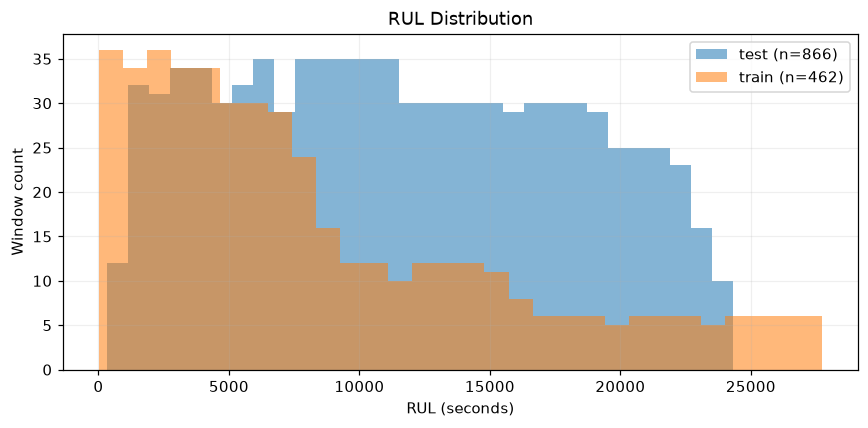

In [27]:
prepared_cache_root = PROJECT_ROOT / 'artifacts' / 'pronostia_cache'
if prepared_cache_root.is_dir():
    official_index = pd.read_csv(prepared_cache_root / 'official' / 'cache_index.csv')
    figure, axis = plt.subplots(figsize=(8, 4))
    for split_name, rows in official_index.groupby('split'):
        values = rows['rul_seconds'].dropna().to_numpy()
        axis.hist(values, bins=30, alpha=0.55, label=f'{split_name} (n={len(values)})')
    axis.set(title='RUL Distribution', xlabel='RUL (seconds)', ylabel='Window count')
    axis.legend()
    axis.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print(f'Prepared cache not found: {prepared_cache_root}')


### Define Moments

In [28]:
class Moments:

    def __init__(self, shape):
        self.count = np.zeros(shape, np.int64)
        self.mean = np.zeros(shape, np.float64)
        self.m2 = np.zeros(shape, np.float64)

    def update(self, x, valid=None):
        x = np.asarray(x, dtype=np.float64)
        valid = np.ones(x.shape, bool) if valid is None else valid
        n = valid.sum(axis=0)
        mean = np.divide(np.where(valid, x, 0).sum(axis=0), n, out=np.zeros_like(self.mean), where=n > 0)
        m2 = np.where(valid, (x - mean) ** 2, 0).sum(axis=0)
        total = self.count + n
        delta = mean - self.mean
        self.mean += np.divide(delta * n, total, out=np.zeros_like(mean), where=total > 0)
        self.m2 += m2 + np.divide(delta ** 2 * self.count * n, total, out=np.zeros_like(mean), where=total > 0)
        self.count = total

    def artifact(self, epsilon):
        std = np.sqrt(np.divide(self.m2, self.count, out=np.zeros_like(self.mean), where=self.count > 0))
        return {'count': self.count.tolist(), 'mean': self.mean.tolist(), 'std': np.maximum(std, epsilon).tolist()}


### Define fit_scaler

In [29]:
def fit_scaler(shards, train_ids, config_hash, split_hash, epsilon=1e-06):
    vib = Moments((2,))
    temp = None
    handcrafted = None
    handcrafted_names = None
    for bearing in train_ids:
        with np.load(shards[bearing], allow_pickle=False) as z:
            x, t, mask = (z['vibration'], z['temperature'], z['temperature_mask'])
            vib.update(x.transpose(0, 2, 1).reshape(-1, 2))
            flat_t = t.reshape(-1, 1) if t.ndim == 3 else t
            flat_mask = mask.reshape(-1, 1) if t.ndim == 3 else mask
            if temp is None:
                temp = Moments((flat_t.shape[-1],))
            temp.update(flat_t, ~flat_mask)
            if 'handcrafted_features' in z.files:
                values = z['handcrafted_features']
                names = z['handcrafted_feature_names'].astype(str).tolist()
                if handcrafted is None:
                    handcrafted = Moments((values.shape[-1],))
                    handcrafted_names = names
                elif names != handcrafted_names:
                    raise ValueError('inconsistent handcrafted feature schema')
                handcrafted.update(values, np.isfinite(values))
    if temp is None:
        raise ValueError('no training shards')
    result = {'train_bearings': list(train_ids), 'config_hash': config_hash, 'split_hash': split_hash, 'epsilon': epsilon,
              'vibration': vib.artifact(epsilon), 'temperature': temp.artifact(epsilon)}
    if handcrafted is not None:
        result['handcrafted'] = handcrafted.artifact(epsilon)
        result['handcrafted_feature_names'] = handcrafted_names
    result['hash'] = fingerprint(result)
    return result


### Define scale_arrays

In [30]:
def scale_arrays(x, t, mask, scaler):
    v, s = (scaler['vibration'], scaler['temperature'])
    x = ((x - np.asarray(v['mean'])[None, :, None]) / np.asarray(v['std'])[None, :, None]).astype(np.float32)
    mean, std = (np.asarray(s['mean']), np.asarray(s['std']))
    if t.ndim == 3:
        mean, std = (mean.reshape(1, 1, 1), std.reshape(1, 1, 1))
    t = np.where(mask, 0, (t - mean) / std).astype(np.float32)
    return (x, t)


def scale_handcrafted_features(features, scaler):
    if 'handcrafted' not in scaler:
        raise ValueError('handcrafted scaler is missing')
    values = np.asarray(features, dtype=np.float64)
    missing = ~np.isfinite(values)
    mean = np.asarray(scaler['handcrafted']['mean'], dtype=np.float64)
    std = np.asarray(scaler['handcrafted']['std'], dtype=np.float64)
    scaled = np.where(missing, 0.0, (values - mean) / std).astype(np.float32)
    return scaled, missing


### Define window_starts

In [31]:
def window_starts(indices, times, length=32, stride=16, max_gap_s=15, include_last=False):
    if length < 1 or stride < 1:
        raise ValueError('length and stride must be positive')
    indices, times = (np.asarray(indices), np.asarray(times))
    starts = []
    breaks = np.flatnonzero((np.diff(indices) != 1) | (np.diff(times) <= 0) | (np.diff(times) > max_gap_s)) + 1
    bounds = np.r_[0, breaks, len(times)]
    for a, b in zip(bounds[:-1], bounds[1:]):
        starts.extend(range(int(a), int(b) - length + 1, stride))
        if include_last and b - a >= length and (int(b) - length not in starts):
            starts.append(int(b) - length)
    return np.asarray(starts, dtype=np.int64)


### Define detect_delimiter

In [32]:
def detect_delimiter(text):
    first = text.strip().splitlines()[0] if text.strip() else ''
    delimiter = max((',', ';', '\t'), key=first.count)
    if not first.count(delimiter):
        raise ValueError('empty file or no supported delimiter')
    return delimiter


### Define detect_header

In [33]:
def detect_header(first, delimiter):
    numeric = []
    for field in first.split(delimiter):
        try:
            float(field)
            numeric.append(True)
        except ValueError:
            numeric.append(False)
    if any(numeric) and (not all(numeric)):
        raise ValueError('malformed first row mixes numbers and text')
    return not all(numeric)


### Define load_numeric_rows

In [34]:
def load_numeric_rows(text, delimiter, header):
    try:
        return np.loadtxt(StringIO(text), delimiter=delimiter, skiprows=int(header), ndmin=2)
    except ValueError as exc:
        raise ValueError(f'malformed numeric rows: {exc}') from exc


### Define validate_csv_schema

In [35]:
def validate_csv_schema(data, modality, expected_samples):
    if modality not in ('acc', 'temp'):
        raise ValueError('unknown modality')
    columns = 6 if modality == 'acc' else 5
    if data.size == 0 or data.shape[1] != columns:
        raise ValueError(f'expected {columns} columns')
    if not np.isfinite(data).all():
        raise ValueError('NaN/Inf present')
    if modality == 'acc' and len(data) != expected_samples:
        raise ValueError('invalid vibration sample count')


### Define parse_clock_fields

In [36]:
def parse_clock_fields(clock, modality, fraction_scale):
    scale = 1000000.0 if modality == 'acc' else fraction_scale
    if (clock[:, :3] < 0).any() or (clock[:, 0] >= 24).any() or (clock[:, 1:3] >= 60).any() or (clock[:, 3] < 0).any() or (clock[:, 3] > scale if modality == 'acc' else clock[:, 3] >= scale).any():
        raise ValueError('timestamp field out of range')
    times = unwrap_clock(clock[:, 0] * 3600 + clock[:, 1] * 60 + clock[:, 2] + clock[:, 3] / scale)
    if (np.diff(times) <= 0).any():
        raise ValueError('timestamps not increasing inside file')
    return (times, scale)


### Define parse_csv

In [37]:
def parse_csv(path, modality, expected_acc_samples=2560, temp_fraction_scale=10, raw_bytes=None):
    text = (raw_bytes.decode('utf-8-sig') if raw_bytes is not None else Path(path).read_text(encoding='utf-8-sig')).strip()
    delimiter = detect_delimiter(text)
    header = detect_header(text.splitlines()[0], delimiter)
    data = load_numeric_rows(text, delimiter, header)
    validate_csv_schema(data, modality, expected_acc_samples)
    times, scale = parse_clock_fields(data[:, :4], modality, temp_fraction_scale)
    schema = {'delimiter': delimiter, 'header': header, 'columns': data.shape[1], 'rows': len(data), 'fraction_scale': scale, 'fraction_rollover_rows': int((data[:, 3] == scale).sum()), 'median_sample_interval_s': float(np.median(np.diff(times))) if len(times) > 1 else None}
    return Parsed(data[:, 4:].T.astype(np.float32), times, schema)


### Define scan_dataset_structure

In [38]:
def scan_dataset_structure(root):
    tasks, issues = ([], [])
    expected = {'Learning_set': LEARNING, 'Test_set': TEST, 'Full_Test_Set': TEST}
    for subset, bearings in expected.items():
        if not (root / subset).is_dir():
            issues.append({'severity': 'ERROR' if subset != 'Full_Test_Set' else 'WARNING', 'reason': 'missing subset', 'path': subset})
            continue
        actual = {p.name for p in (root / subset).iterdir() if p.is_dir()}
        for bearing in sorted(set(bearings) - actual):
            issues.append({'severity': 'ERROR', 'reason': 'missing bearing', 'path': f'{subset}/{bearing}'})
        for bearing in sorted(actual, key=natural_key):
            if bearing not in bearings:
                issues.append({'severity': 'ERROR', 'reason': 'unexpected bearing', 'path': f'{subset}/{bearing}'})
                continue
            for path in sorted((root / subset / bearing).glob('*.csv'), key=natural_key):
                modality = path.stem.split('_')[0]
                if modality not in ('acc', 'temp'):
                    issues.append({'severity': 'ERROR', 'reason': 'unknown CSV modality', 'path': str(path.relative_to(root))})
                    continue
                tasks.append((path, subset, bearing, modality))
    return (tasks, issues)


### Define scan_inventory_files

In [39]:
def scan_inventory_files(root, tasks, config):
    with ThreadPoolExecutor(max_workers=config.get('inventory_workers', 8)) as pool:
        result = list(pool.map(lambda task: inspect_file(task[0], root, task[1], task[2], task[3], config), tasks))
    for record in result:
        record['condition_id'] = 'OC' + str(int(record['bearing_id'][7]))
    return result


### Define validate_filename_indices

In [40]:
def validate_filename_indices(records):
    issues = []
    groups = defaultdict(list)
    for r in records:
        groups[r['subset'], r['bearing_id'], r['modality']].append(r)
    for key, group in groups.items():
        ids = [r['acquisition_index'] for r in group if 'acquisition_index' in r]
        if not ids:
            continue
        missing = sorted(set(range(1, max(ids) + 1)) - set(ids))
        duplicates = sorted((i for i, n in Counter(ids).items() if n > 1))
        if missing or duplicates:
            issues.append({'severity': 'WARNING', 'reason': 'filename gaps/duplicates', 'path': '/'.join(key), 'missing': missing, 'duplicates': duplicates})
    return issues


### Define validate_learning_terminals

In [41]:
def validate_learning_terminals(records, expected_terminal_indices):
    for bearing, terminal in expected_terminal_indices.items():
        group = [r for r in records if r['subset'] == 'Learning_set' and r['bearing_id'] == bearing and (r['modality'] == 'acc')]
        selected = [r for r in group if r.get('acquisition_index') == terminal]
        if len(selected) != 1 or selected[0]['data_status'] != 'ok':
            raise ValueError(f'terminal acquisition missing/quarantined: {bearing}/{terminal}')
        if max((r.get('acquisition_index', 0) for r in group)) != terminal:
            raise ValueError(f'unexpected learning terminal index: {bearing}')


### Define build_acquisition_records

In [42]:
def build_acquisition_records(records, config):
    rows, repairs = ([], [])
    groups = defaultdict(list)
    for r in records:
        if r['modality'] == 'acc' and r['data_status'] == 'ok':
            groups[r['subset'], r['bearing_id']].append(r)
    for (subset, bearing), group in sorted(groups.items()):
        group = sorted(group, key=lambda r: r['acquisition_index'])
        raw_times = unwrap_clock(np.array([r['first_timestamp'] for r in group]))
        times = raw_times.copy()
        if config.get('clock_repair') == 'bracketed_nominal_interval':
            times, fixes = repair_acquisition_clock([r['acquisition_index'] for r in group], times, config['acquisition_period_s'], config.get('clock_repair_tolerance_s', 0.001))
            repairs.extend((dict(f, subset=subset, bearing_id=bearing) for f in fixes))
        if (np.diff(times) <= 0).any():
            raise ValueError('non-increasing bearing clock')
        rpm, load = CONDITIONS[int(bearing[7])]
        for r, t, rt in zip(group, times, raw_times):
            rows.append({'subset': subset, 'bearing_id': bearing, 'condition_id': r['condition_id'], 'acquisition_index': r['acquisition_index'], 'acc_path': r['path'], 'acc_timestamp': float(t), 'raw_acc_timestamp': float(rt), 'clock_repaired': bool(t != rt), 'rpm': rpm, 'load_n': load, 'n_acc_samples': r['rows'], 'data_status': 'warning' if t != rt else 'ok', 'split': 'unassigned', 'fold': '', 'rul_seconds': None, 'rul_cycles': None, 'temp_timestamp': None, 'alignment_delta_s': None, 'temp_missing_mask': True})
    if not rows:
        raise ValueError('no valid vibration acquisitions')
    return (pd.DataFrame(rows), repairs)


### Define analyze_inventory_quality

In [43]:
def analyze_inventory_quality(records, structure_issues, index_issues, repairs):
    hashes = defaultdict(list)
    for r in records:
        hashes[r['sha256']].append(r['path'])
    issues = structure_issues + index_issues + [{'severity': 'WARNING', 'reason': r['reason'], 'path': r['path']} for r in records if r['data_status'] != 'ok']
    issues += [dict(f, severity='WARNING') for f in repairs]
    return {'file_count': len(records), 'source_hash': fingerprint([{k: r.get(k) for k in ('path', 'sha256', 'data_status')} for r in records]), 'quarantined_files': sum((r['data_status'] != 'ok' for r in records)), 'issues': issues, 'duplicate_content_groups': [v for v in hashes.values() if len(v) > 1], 'counts': dict(Counter(('/'.join((r[k] for k in ('subset', 'bearing_id', 'modality'))) for r in records)))}


### Define ground_truth_comparison

In [44]:
def ground_truth_comparison(manifest, ground_truth):
    result = []
    for row in ground_truth.to_dict('records'):
        bearing = row['bearing_id']
        cut = manifest[(manifest.subset == 'Test_set') & (manifest.bearing_id == bearing)].acc_timestamp.max()
        terminal = manifest[(manifest.subset == 'Full_Test_Set') & (manifest.bearing_id == bearing)].acc_timestamp.max()
        derived = float(terminal - cut) if pd.notna(terminal) else None
        difference = abs(derived - float(row['rul_seconds'])) if derived is not None else None
        result.append({**row, 'test_cut_timestamp': float(cut), 'full_test_terminal_timestamp': float(terminal) if pd.notna(terminal) else None, 'derived_rul_seconds': derived, 'configured_rul_seconds': float(row['rul_seconds']), 'absolute_difference_seconds': difference, 'verified_against_full_test': difference is not None and difference <= 0.001, 'verification_status': 'MATCH' if difference is not None and difference <= 0.001 else 'HIGH_WARNING_MISMATCH'})
    return pd.DataFrame(result)


### Define bearing_frames

In [45]:
def bearing_frames(manifest):
    return {b: frame.sort_values('acquisition_index').copy() for (_, b), frame in manifest[manifest.subset != 'Full_Test_Set'].groupby(['subset', 'bearing_id'], sort=True)}


### Define label_bearing

In [46]:
def label_bearing(frame, config):
    subset = frame.subset.iloc[0]
    bearing = frame.bearing_id.iloc[0]
    seconds, cycles = absolute_rul(frame.acc_timestamp.to_numpy(), subset, config['test_rul_at_cut_seconds'].get(bearing), config['acquisition_period_s'])
    result = frame.copy()
    result['rul_seconds'] = seconds
    result['rul_cycles'] = cycles
    return result


### Define load_bearing_temperature

In [47]:
def load_bearing_temperature(root, records, frame, config):
    selected = [r for r in records if r['subset'] == frame.subset.iloc[0] and r['bearing_id'] == frame.bearing_id.iloc[0]]
    return load_temperature(root, selected, frame.acc_timestamp.iloc[0], config['temperature'])


### Define align_bearing_temperature

In [48]:
def align_bearing_temperature(stream, frame, config):
    tt, tv, tp, _ = stream
    features, mask, matched, delta = causal_temperature(tt, tv, frame.acc_timestamp.to_numpy(), config['temperature'])
    return {'temperature': features, 'temperature_mask': mask, 'matched': matched, 'delta': delta}


### Define validate_temperature_alignment

In [49]:
def validate_temperature_alignment(aligned, config):
    t, m, d = (aligned['temperature'], aligned['temperature_mask'], aligned['delta'])
    if m.dtype != np.bool_ or m.shape != t.shape:
        raise ValueError('temperature mask dtype/shape')
    finite = np.isfinite(d)
    if (d[finite] < 0).any():
        raise ValueError('future temperature used')
    has_current = ~m[:, :, -1].reshape(len(m)) if m.ndim == 3 else ~m[:, 0]
    if (d[has_current] > config['temperature']['max_alignment_gap_s']).any():
        raise ValueError('temperature gap exceeded')
    if not np.isfinite(t).all():
        raise ValueError('nonfinite temperature')


### Define transform_bearing_vibration

In [50]:
def transform_bearing_vibration(root, frame, config):
    return np.stack([transform_vibration(parse_csv(root / path, 'acc').data, config['vibration']) for path in frame.acc_path])


### Define assemble_bearing_shard

In [51]:
def assemble_bearing_shard(frame, vibration, aligned):
    return {'vibration': vibration, 'temperature': aligned['temperature'], 'temperature_mask': aligned['temperature_mask'], 'rul': frame.rul_seconds.to_numpy(dtype=np.float32), 'rul_cycles': frame.rul_cycles.to_numpy(dtype=np.float32), 'timestamp': frame.acc_timestamp.to_numpy(), 'acquisition_index': frame.acquisition_index.to_numpy(), 'raw_paths': frame.acc_path.to_numpy(dtype=str), 'bearing_id': np.asarray(frame.bearing_id.iloc[0]), 'condition_id': np.asarray(frame.condition_id.iloc[0])}


### Define export_acquisition_shards

In [52]:
def export_acquisition_shards(output, arrays):
    folder = output / 'acquisitions'
    folder.mkdir(parents=True, exist_ok=True)
    paths = {}
    for bearing, values in arrays.items():
        paths[bearing] = folder / f'{bearing}.npz'
        np.savez(paths[bearing], **values)
    return paths


### Define temperature_coverage

In [53]:
def temperature_coverage(records, frames, streams, aligned):
    rows = []
    for b, frame in frames.items():
        subset = frame.subset.iloc[0]
        files = [r for r in records if r['subset'] == subset and r['bearing_id'] == b]
        tt = streams[b][0]
        mask = aligned[b]['temperature_mask']
        any_valid = (~mask).reshape(len(mask), -1).any(axis=1)
        rows.append({'bearing_id': b, 'subset': subset, 'condition_id': frame.condition_id.iloc[0], 'acc_file_count': sum((r['modality'] == 'acc' for r in files)), 'temp_file_count': sum((r['modality'] == 'temp' for r in files)), 'first_acc_timestamp': float(frame.acc_timestamp.iloc[0]), 'last_acc_timestamp': float(frame.acc_timestamp.iloc[-1]), 'first_temp_timestamp': float(tt[0]) if len(tt) else None, 'last_temp_timestamp': float(tt[-1]) if len(tt) else None, 'aligned_acquisition_count': int(any_valid.sum()), 'aligned_acquisition_percent': float(any_valid.mean() * 100), 'missing_element_percent': float(mask.mean() * 100), 'high_warning': bool(mask.all())})
    return pd.DataFrame(rows)


### Display temperature coverage

In [54]:
prepared_cache_root = PROJECT_ROOT / 'artifacts' / 'pronostia_cache'
if prepared_cache_root.is_dir():
    official_manifest = pd.read_csv(prepared_cache_root / 'official' / 'manifest.csv')
    temperature_coverage_summary = official_manifest.groupby('split', as_index=False).agg(
        acquisitions=('bearing_id', 'size'),
        missing_temperature=('temp_missing_mask', 'sum'),
    )
    temperature_coverage_summary['available_temperature'] = (
        temperature_coverage_summary['acquisitions'] - temperature_coverage_summary['missing_temperature']
    )
    temperature_coverage_summary['coverage_percent'] = (
        100.0 * temperature_coverage_summary['available_temperature'] / temperature_coverage_summary['acquisitions']
    ).round(2)
    display(temperature_coverage_summary)
else:
    print(f'Prepared cache not found: {prepared_cache_root}')


,split,acquisitions,missing_temperature,available_temperature,coverage_percent
0,test,13959,3622,10337,74.05
1,train,7534,2464,5070,67.29


### Display the missing-temperature policy


In [55]:
missing_policy = CONFIG['temperature']['missing_policy']
policy_rows = [
    {'case': 'Partial temperature history', 'action': missing_policy['partial_history']},
    {'case': 'Fully missing temperature bearing', 'action': missing_policy['fully_missing_bearing']},
    {'case': 'Standardized missing value', 'action': f"{missing_policy['standardized_fill_value']} ({missing_policy['fill_interpretation']})"},
    {'case': 'Cross-bearing imputation', 'action': missing_policy['cross_bearing_imputation']},
    {'case': 'Future-value imputation', 'action': missing_policy['future_value_imputation']},
    {'case': 'Exported masks', 'action': ', '.join(missing_policy['exported_masks'])},
]
display(pd.DataFrame(policy_rows))


,case,action
0,Partial temperature history,preserve_per_element_mask
1,Fully missing temperature bearing,preserve_full_mask
2,Standardized missing value,0.0 (training_mean_after_zscore)
3,Cross-bearing imputation,forbidden
4,Future-value imputation,forbidden
5,Exported masks,"temperature_mask, handcrafted_feature_mask"


### Define make_temperature_report

In [56]:
def make_temperature_report(coverage, aligned):
    result = {}
    for row in coverage.to_dict('records'):
        row = {k: None if isinstance(v, float) and (not np.isfinite(v)) else v for k, v in row.items()}
        delta = aligned[row['bearing_id']]['delta']
        delta = delta[np.isfinite(delta)]
        result[row['bearing_id']] = {**row, 'alignment_delta_quantiles_s': np.quantile(delta, [0, 0.5, 0.95, 1]).tolist() if len(delta) else []}
    return result


### Define make_label_report

In [57]:
def make_label_report(frames):
    return {b: {'subset': f.subset.iloc[0], 'acquisitions': len(f), 'observed_duration_s': float(f.acc_timestamp.iloc[-1] - f.acc_timestamp.iloc[0]), 'rul_min_s': float(f.rul_seconds.min()), 'rul_max_s': float(f.rul_seconds.max()), 'monotonic': bool((np.diff(f.rul_seconds) <= 0).all())} for b, f in frames.items()}


### Define scale_fold_shards

In [58]:
def scale_fold_shards(paths, split, scaler):
    for role in ('train', 'validation', 'test'):
        for b in split[role]:
            with np.load(paths[b], allow_pickle=False) as z:
                arrays = {k: z[k] for k in z.files}
            x, t = scale_arrays(arrays['vibration'], arrays['temperature'], arrays['temperature_mask'], scaler)
            arrays['vibration'] = x
            arrays['temperature'] = t
            if 'handcrafted_features' in arrays:
                features, feature_mask = scale_handcrafted_features(arrays['handcrafted_features'], scaler)
                arrays['handcrafted_features'] = features
                arrays['handcrafted_feature_mask'] = feature_mask
            arrays['scaler_hash'] = np.asarray(scaler['hash'])
            yield (role, b, arrays)


### Define export_scaled_shards

In [59]:
def export_scaled_shards(folder, values):
    for role, b, arrays in values:
        path = folder / 'shards' / role / f'{b}.npz'
        path.parent.mkdir(parents=True, exist_ok=True)
        np.savez(path, **arrays)


### Define window_metadata

In [60]:
def window_metadata(arrays, role, config):
    stride = config['stride_train'] if role == 'train' else config['stride_eval']
    starts = window_starts(arrays['acquisition_index'], arrays['timestamp'], config['sequence_length'], stride, config['max_window_gap_s'], include_last=role != 'train')
    return {'window_starts': starts, 'sequence_length': np.asarray(config['sequence_length'])}


### Define export_window_metadata

In [61]:
def export_window_metadata(folder, split, config):
    for role in ('train', 'validation', 'test'):
        for b in split[role]:
            path = folder / 'shards' / role / f'{b}.npz'
            with np.load(path, allow_pickle=False) as z:
                arrays = {k: z[k] for k in z.files}
            arrays.update(window_metadata(arrays, role, config))
            np.savez(path, **arrays)


### Define build_cache_index

In [62]:
def build_cache_index(folder, split):
    rows = []
    for role in ('train', 'validation', 'test'):
        for b in split[role]:
            path = folder / 'shards' / role / f'{b}.npz'
            with np.load(path, allow_pickle=False) as z:
                for start in z['window_starts']:
                    end = int(start + z['sequence_length'] - 1)
                    rows.append({'fold': str(split['fold']), 'split': role, 'bearing_id': b, 'condition_id': str(z['condition_id']), 'shard_path': path.relative_to(folder).as_posix(), 'start': int(start), 'end_index': int(z['acquisition_index'][end]), 'end_timestamp': float(z['timestamp'][end]), 'rul_seconds': float(z['rul'][end])})
    return pd.DataFrame(rows)


### Display prepared cache window counts

In [63]:
prepared_cache_root = PROJECT_ROOT / 'artifacts' / 'pronostia_cache'
if prepared_cache_root.is_dir():
    window_count_rows = []
    for split_root in [*(prepared_cache_root / f'fold_{i}' for i in range(6)), prepared_cache_root / 'official']:
        index = pd.read_csv(split_root / 'cache_index.csv')
        for split_name, count in index.groupby('split').size().items():
            window_count_rows.append({'dataset': split_root.name, 'split': split_name, 'windows': int(count)})
    prepared_window_counts = pd.DataFrame(window_count_rows)
    display(prepared_window_counts)
else:
    print(f'Prepared cache not found: {prepared_cache_root}')


,dataset,split,windows
0,fold_0,train,288
1,fold_0,validation,175
2,fold_1,train,409
3,fold_1,validation,54
4,fold_2,train,407
5,fold_2,validation,56
6,fold_3,train,414
7,fold_3,validation,49
8,fold_4,train,431
9,fold_4,validation,32


### Define fold_manifest

In [64]:
def fold_manifest(manifest, split):
    roles = {b: role for role in ('train', 'validation', 'test') for b in split[role]}
    result = manifest[manifest.subset != 'Full_Test_Set'].copy()
    result['split'] = result.bearing_id.map(roles).fillna('excluded')
    result['fold'] = str(split['fold'])
    return result


### Define cache_identity

In [65]:
def cache_identity(source_hash, config, split, scaler):
    semantic = {k: v for k, v in config.items() if k not in ('raw_root', 'output_root', 'inventory_workers')}
    identity = {'source_hash': source_hash, 'config_hash': fingerprint(config), 'semantic_config_hash': fingerprint(semantic), 'split_hash': fingerprint(split), 'scaler_hash': scaler['hash']}
    identity['identity'] = fingerprint([identity[k] for k in ('source_hash', 'config_hash', 'split_hash', 'scaler_hash')])
    return identity


### Define verify_source

In [66]:
def verify_source(parent, raw_root=None):
    parent = Path(parent)
    config = yaml.safe_load((parent / 'preprocessing.yaml').read_text(encoding='utf-8'))
    configured_root = raw_root if raw_root is not None else config.get('raw_root')
    if configured_root is None:
        raise FileNotFoundError('raw root is not configured; pass raw_root explicitly for strict raw verification')
    root = Path(configured_root).expanduser()
    if not root.is_absolute():
        root = (parent / root).resolve()
    if not root.is_dir():
        raise FileNotFoundError(
            f'raw root not found: {root}. Pass dataset_kwargs={{"raw_root": r"..."}} when raw data was moved, '
            'or dataset_kwargs={"verify_raw": False} when loading a trusted transferred cache.'
        )
    records = pd.read_csv(parent / 'manifest_all_files.csv').to_dict('records')
    paths = {r['path'] for r in records}
    actual = {p.relative_to(root).as_posix() for subset in ('Learning_set', 'Test_set', 'Full_Test_Set') for p in (root / subset).rglob('*.csv')}
    if paths != actual:
        raise ValueError('raw files added/removed')
    for r in records:
        if hashlib.sha256((root / r['path']).read_bytes()).hexdigest() != r['sha256']:
            raise ValueError('raw checksum changed')
    return fingerprint([{k: r[k] for k in ('path', 'sha256', 'data_status')} for r in records])


### Define verify_identity

In [67]:
def verify_identity(folder, expected_config=None, verify_raw=True, verified_source_hash=None, raw_root=None):
    folder = Path(folder)
    read = lambda p: json.loads(p.read_text(encoding='utf-8'))
    identity = read(folder / 'cache_identity.json')
    scaler = read(folder / 'scaler.json')
    split = read(folder / 'split.json')
    config = yaml.safe_load((folder.parent / 'preprocessing.yaml').read_text(encoding='utf-8'))
    semantic = lambda c: {k: v for k, v in c.items() if k not in ('raw_root', 'output_root', 'inventory_workers')}
    full_config_matches = fingerprint(config) == identity['config_hash']
    portable_config_matches = identity.get('semantic_config_hash') == fingerprint(semantic(config))
    if not (full_config_matches or portable_config_matches):
        raise ValueError('config_hash mismatch')
    current = {'split_hash': fingerprint(split), 'scaler_hash': fingerprint({k: v for k, v in scaler.items() if k != 'hash'})}
    for key, value in current.items():
        if value != identity[key]:
            raise ValueError(f'{key} mismatch')
    if scaler['hash'] != identity['scaler_hash']:
        raise ValueError('scaler hash mismatch')
    if scaler.get('config_hash') != identity['config_hash'] or scaler.get('split_hash') != identity['split_hash']:
        raise ValueError('scaler provenance mismatch')
    if expected_config is not None:
        if fingerprint(semantic(config)) != fingerprint(semantic(expected_config)):
            raise ValueError('requested preprocessing config changed')
        raw_root = raw_root or expected_config.get('raw_root')
    source = verified_source_hash
    if verify_raw and source is None:
        source = verify_source(folder.parent, raw_root)
    if source is not None and source != identity['source_hash']:
        raise ValueError('source identity mismatch')
    if identity['identity'] != fingerprint([identity[k] for k in ('source_hash', 'config_hash', 'split_hash', 'scaler_hash')]):
        raise ValueError('combined identity mismatch')
    return identity


### Define PronostiaDataset

In [68]:
class PronostiaDataset(Dataset):

    def __init__(self, artifact_dir, split='train', max_cached_bearings=2, inference_only=False, expected_config=None, verify_raw=True, verified_source_hash=None, raw_root=None):
        self.root = Path(artifact_dir)
        self.inference_only = inference_only
        self.max_cached = max_cached_bearings
        if max_cached_bearings < 1:
            raise ValueError('max_cached_bearings must be positive')
        self.identity = verify_identity(self.root, expected_config, verify_raw, verified_source_hash, raw_root)
        with (self.root / 'cache_index.csv').open(encoding='utf-8', newline='') as f:
            self.rows = [r for r in csv.DictReader(f) if r['split'] == split]
        self.cache = OrderedDict()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        if index < 0 or index >= len(self):
            raise IndexError(index)
        row = self.rows[index]
        key = row['shard_path']
        if key not in self.cache:
            with np.load(self.root / key, allow_pickle=False) as z:
                self.cache[key] = {k: z[k] for k in z.files}
            if str(self.cache[key]['scaler_hash']) != self.identity['scaler_hash']:
                self.cache.pop(key)
                raise ValueError('shard scaler mismatch')
            while len(self.cache) > self.max_cached:
                self.cache.popitem(last=False)
        self.cache.move_to_end(key)
        z = self.cache[key]
        start = int(row['start'])
        end = start + int(z['sequence_length']) - 1
        label = float(z['rul'][end])
        if not np.isfinite(label) and (not self.inference_only):
            raise ValueError('test RUL unavailable')
        sample = {'vibration': torch.from_numpy(z['vibration'][start:end + 1].copy()),
                  'temperature': torch.from_numpy(z['temperature'][start:end + 1].copy()),
                  'temperature_mask': torch.from_numpy(z['temperature_mask'][start:end + 1].copy()),
                  'rul': torch.tensor([label], dtype=torch.float32), 'rul_valid': np.isfinite(label),
                  'bearing_id': row['bearing_id'], 'condition_id': row['condition_id'],
                  'end_index': int(row['end_index']), 'end_timestamp': float(row['end_timestamp']),
                  'raw_end_path': str(z['raw_paths'][end])}
        if 'handcrafted_features' in z:
            sample['handcrafted_features'] = torch.from_numpy(z['handcrafted_features'][start:end + 1].copy())
            sample['handcrafted_feature_mask'] = torch.from_numpy(z['handcrafted_feature_mask'][start:end + 1].copy())
        return sample


### Define pronostia_loader

In [69]:
def pronostia_loader(artifact_dir, split, batch_size=32, num_workers=0, seed=42, dataset_kwargs=None, loader_kwargs=None):
    """Create a portable DataLoader from a validated artifact cache.

    For relocated raw data, pass dataset_kwargs={'raw_root': r'path'}.
    Raw verification is opt-in for transferred caches: pass
    dataset_kwargs={'verify_raw': True, 'raw_root': r'path'}.
    """
    dataset_options = dict(dataset_kwargs or {})
    dataset_options.setdefault('verify_raw', False)
    dataset = PronostiaDataset(artifact_dir, split=split, **dataset_options)
    kwargs = dict(loader_kwargs or {})
    kwargs.setdefault('shuffle', split == 'train')
    kwargs.setdefault('generator', torch.Generator().manual_seed(seed))
    return DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, **kwargs)


### Display a prepared batch contract

In [70]:
prepared_cache_root = PROJECT_ROOT / 'artifacts' / 'pronostia_cache'
if prepared_cache_root.is_dir():
    prepared_train_loader = pronostia_loader(prepared_cache_root / 'official', 'train', batch_size=32)
    prepared_train_batch = next(iter(prepared_train_loader))
    batch_contract = pd.DataFrame([
        {'field': key, 'shape': str(tuple(value.shape)), 'dtype': str(value.dtype)}
        for key, value in prepared_train_batch.items() if hasattr(value, 'shape')
    ])
    display(batch_contract)
else:
    print(f'Prepared cache not found: {prepared_cache_root}')


,field,shape,dtype
0,vibration,"(32, 32, 2, 1024)",torch.float32
1,temperature,"(32, 32, 1, 64)",torch.float32
2,temperature_mask,"(32, 32, 1, 64)",torch.bool
3,rul,"(32, 1)",torch.float32
4,rul_valid,"(32,)",torch.bool
5,end_index,"(32,)",torch.int64
6,end_timestamp,"(32,)",torch.float64


### Define validate_split_scaler

In [71]:
def validate_split_scaler(folder):
    folder = Path(folder)
    split = json.loads((folder / 'split.json').read_text())
    scaler = json.loads((folder / 'scaler.json').read_text())
    assert_disjoint(split)
    if scaler['train_bearings'] != split['train']:
        raise ValueError('scaler not fit on train bearings')
    index = pd.read_csv(folder / 'cache_index.csv')
    if (index.groupby('bearing_id').split.nunique() > 1).any():
        raise ValueError('bearing windows cross splits')


### Define validate_window_shard

In [72]:
def validate_window_shard(arrays, role, config):
    length = int(arrays['sequence_length'])
    for start in arrays['window_starts']:
        end = int(start + length - 1)
        times = arrays['timestamp'][start:end + 1]
        if end >= len(arrays['vibration']) or (np.diff(arrays['acquisition_index'][start:end + 1]) != 1).any():
            raise ValueError('window boundary')
        if (np.diff(times) <= 0).any() or (np.diff(times) > config['max_window_gap_s']).any():
            raise ValueError('window cadence')
    if role != 'train' and len(arrays['window_starts']):
        if int(arrays['window_starts'][-1] + length - 1) != len(arrays['vibration']) - 1:
            raise ValueError('endpoint not included')


### Define validate_temperature_shard

In [73]:
def validate_temperature_shard(arrays):
    t, m = (arrays['temperature'], arrays['temperature_mask'])
    if m.dtype != np.bool_ or t.shape != m.shape:
        raise ValueError('temperature mask dtype/shape')
    if not np.isfinite(t).all():
        raise ValueError('nonfinite temperature')
    if (t[m] != 0).any():
        raise ValueError('missing temperature must be zero after scaling')


### Define validate_one_shard

In [74]:
def validate_one_shard(path, scaler_hash, learning, debug=False):
    with np.load(path, allow_pickle=False) as z:
        arrays = {k: z[k] for k in z.files}
    if not np.isfinite(arrays['vibration']).all():
        raise ValueError('nonfinite vibration')
    labels = arrays['rul']
    times = arrays['timestamp']
    if not np.isfinite(labels).all() or (labels < 0).any() or (np.diff(labels) > 0).any():
        raise ValueError('invalid RUL')
    if learning and (not debug) and (labels[-1] != 0):
        raise ValueError('last learning RUL must be zero')
    if (np.diff(times) <= 0).any():
        raise ValueError('non-increasing timestamp')
    if str(arrays['scaler_hash']) != scaler_hash:
        raise ValueError('stale shard scaler')
    if 'handcrafted_features' in arrays:
        features = arrays['handcrafted_features']
        feature_mask = arrays.get('handcrafted_feature_mask')
        if feature_mask is None or feature_mask.dtype != np.bool_ or feature_mask.shape != features.shape:
            raise ValueError('handcrafted feature mask dtype/shape')
        if not np.isfinite(features).all() or (features[feature_mask] != 0).any():
            raise ValueError('invalid scaled handcrafted features')
    return arrays


### Define validate_loader_batch

In [75]:
def validate_loader_batch(batch, config):
    for key in ('vibration', 'temperature', 'rul'):
        if not torch.isfinite(batch[key]).all():
            raise ValueError(f'nonfinite batch {key}')
    if batch['temperature_mask'].dtype != torch.bool or batch['temperature_mask'].shape != batch['temperature'].shape:
        raise ValueError('batch mask contract')
    if (batch['temperature'][batch['temperature_mask']] != 0).any():
        raise ValueError('batch missing values not zero')
    expected_l = 1024 if config['vibration']['mode'] == 'resample_1024' else 2560
    if tuple(batch['vibration'].shape[1:]) != (config['sequence_length'], 2, expected_l):
        raise ValueError('batch vibration contract')
    if batch['rul'].shape != (len(batch['rul']), 1):
        raise ValueError('batch target contract')
    if 'handcrafted_features' in batch:
        expected_features = len(handcrafted_feature_names(config))
        if tuple(batch['handcrafted_features'].shape[1:]) != (config['sequence_length'], expected_features):
            raise ValueError('batch handcrafted feature contract')
        if batch['handcrafted_feature_mask'].dtype != torch.bool:
            raise ValueError('batch handcrafted feature mask contract')
        if not torch.isfinite(batch['handcrafted_features']).all():
            raise ValueError('nonfinite batch handcrafted features')


### Define validate_one_loader

In [76]:
def validate_one_loader(folder, role, config):
    loader = pronostia_loader(folder, role, dataset_kwargs={'verify_raw': False})
    count = 0
    trace = None
    for batch in loader:
        validate_loader_batch(batch, config)
        count += len(batch['rul'])
        if trace is None:
            trace = {'bearing_id': batch['bearing_id'][0], 'raw_end_path': batch['raw_end_path'][0], 'end_index': int(batch['end_index'][0]), 'end_timestamp': float(batch['end_timestamp'][0]), 'rul_seconds': float(batch['rul'][0, 0]), 'vibration_shape': list(batch['vibration'].shape), 'temperature_shape': list(batch['temperature'].shape)}
    if count != len(loader.dataset):
        raise ValueError('full pass incomplete')
    return {'windows': count, 'trace': trace}


### Define benchmark_loader

In [77]:
def benchmark_loader(folder, role):
    loader = pronostia_loader(folder, role, dataset_kwargs={'verify_raw': False})
    times = []
    count = 0
    iterator = iter(loader)
    while True:
        start = time.perf_counter()
        try:
            batch = next(iterator)
        except StopIteration:
            break
        times.append(time.perf_counter() - start)
        count += len(batch['rul'])
    total = sum(times)
    return {'windows': count, 'median_ms': float(np.median(times) * 1000) if times else None, 'p95_ms': float(np.quantile(times, 0.95) * 1000) if times else None, 'samples_per_s': count / total if total else None, 'batch_size': 32, 'num_workers': 0}


### Define aggregate_fold_counts

In [78]:
def aggregate_fold_counts(records, manifest, index, split):
    files = pd.DataFrame(records)
    roles = {b: r for r in ('train', 'validation', 'test') for b in split[r]}
    files['split'] = files.bearing_id.map(roles).fillna('excluded')
    files.loc[files.subset == 'Full_Test_Set', 'split'] = 'excluded'
    result = []
    for (subset, condition, role), group in files.groupby(['subset', 'condition_id', 'split']):
        bearings = set(group.bearing_id)
        acq = manifest[(manifest.subset == subset) & manifest.bearing_id.isin(bearings)]
        windows = index[(index.split == role) & index.bearing_id.isin(bearings)] if role != 'excluded' else index.iloc[:0]
        result.append({'subset': subset, 'condition_id': condition, 'split': role, 'bearing_count': len(bearings), 'file_count': len(group), 'acc_file_count': int((group.modality == 'acc').sum()), 'temp_file_count': int((group.modality == 'temp').sum()), 'acquisition_count': len(acq), 'window_count': len(windows)})
    return result


### Define calculate_aliasing_qc

In [79]:
def calculate_aliasing_qc(vibration_config):
    times = np.arange(2560) / 25600
    low = np.tile(np.sin(2 * np.pi * 1000 * times), (2, 1))
    high = np.tile(np.sin(2 * np.pi * 8000 * times), (2, 1))
    rms = lambda x: float(np.sqrt((x[:, 40:-40] ** 2).mean()))
    passband = rms(transform_vibration(low, vibration_config))
    stopband = rms(transform_vibration(high, vibration_config))
    return {'passband_hz': 1000, 'stopband_hz': 8000, 'passband_rms': passband, 'stopband_rms': stopband, 'attenuation_db': 20 * np.log10(stopband / passband), 'pass': bool(passband > 0.65 and stopband < 0.01)}


### Define select_qc_samples

In [80]:
def select_qc_samples(root, manifest, config):
    result = {}
    for bearing in ('Bearing1_1', 'Bearing2_1', 'Bearing3_1'):
        frame = manifest[(manifest.subset == 'Learning_set') & (manifest.bearing_id == bearing)]
        row = frame.iloc[len(frame) // 2]
        raw = parse_csv(root / row.acc_path, 'acc').data
        result[bearing] = {'raw': raw, 'processed': transform_vibration(raw, config['vibration']), 'path': row.acc_path}
    return result


### Define plot_waveform_qc

In [81]:
def plot_waveform_qc(samples):
    fig, axes = plt.subplots(3, 2, figsize=(12, 8), constrained_layout=True)
    for i, (bearing, values) in enumerate(samples.items()):
        for channel in (0, 1):
            ax = axes[i, channel]
            raw = values['raw'][channel]
            x = values['processed'][channel]
            ax.plot(np.arange(len(raw)) / 25600, raw, label='raw', alpha=0.55)
            ax.plot(np.arange(len(x)) / 10240, x, label='resample 2/5', linewidth=0.8)
            ax.set_title(f'{bearing} axis {channel}')
            ax.set_xlabel('seconds')
            ax.legend()
    return fig


### Plot a prepared signal sample

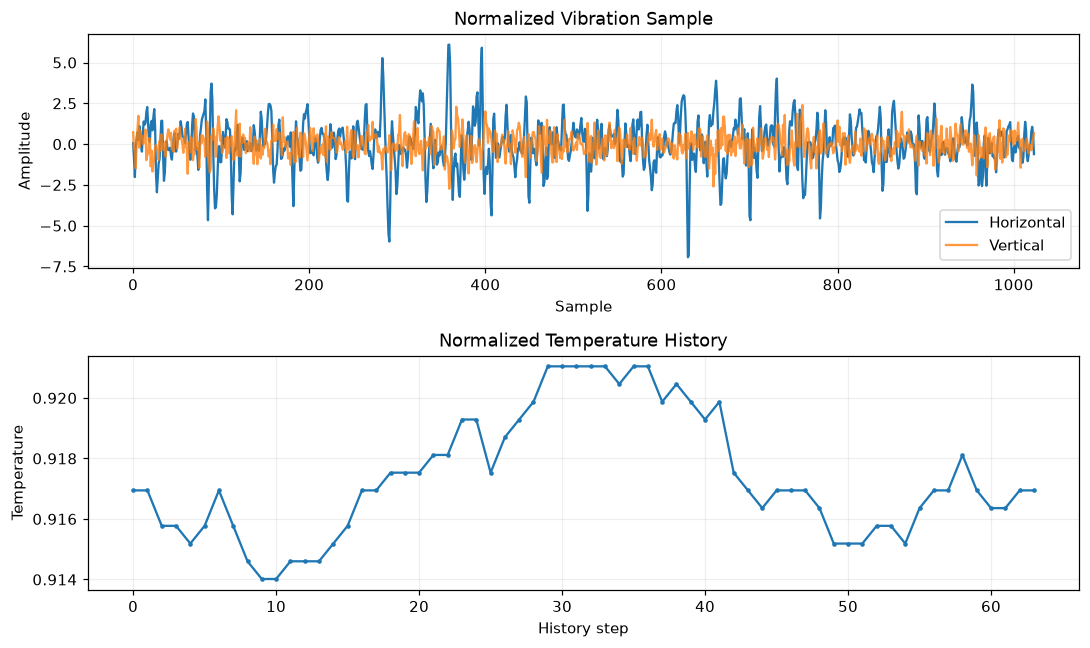

In [82]:
prepared_cache_root = PROJECT_ROOT / 'artifacts' / 'pronostia_cache'
if prepared_cache_root.is_dir():
    preview_loader = pronostia_loader(prepared_cache_root / 'official', 'train', batch_size=1)
    preview_batch = next(iter(preview_loader))
    vibration_sample = preview_batch['vibration'][0, -1].numpy()
    temperature_sample = preview_batch['temperature'][0, -1, 0].numpy()
    temperature_mask = preview_batch['temperature_mask'][0, -1, 0].numpy()
    visible_temperature = np.where(temperature_mask, np.nan, temperature_sample)

    figure, axes = plt.subplots(2, 1, figsize=(10, 6))
    axes[0].plot(vibration_sample[0], label='Horizontal')
    axes[0].plot(vibration_sample[1], label='Vertical', alpha=0.8)
    axes[0].set(title='Normalized Vibration Sample', xlabel='Sample', ylabel='Amplitude')
    axes[0].legend()
    axes[0].grid(alpha=0.2)

    axes[1].plot(visible_temperature, marker='o', markersize=2)
    axes[1].set(title='Normalized Temperature History', xlabel='History step', ylabel='Temperature')
    axes[1].grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print(f'Prepared cache not found: {prepared_cache_root}')


### Define plot_psd_qc

In [83]:
def plot_psd_qc(samples):
    fig, axes = plt.subplots(3, 2, figsize=(12, 8), constrained_layout=True)
    for i, (bearing, values) in enumerate(samples.items()):
        for channel in (0, 1):
            for label, key, fs in [('raw', 'raw', 25600), ('processed', 'processed', 10240)]:
                frequency, power = welch(values[key][channel], fs, nperseg=512)
                axes[i, channel].semilogy(frequency, np.maximum(power, 1e-14), label=label)
            axes[i, channel].set_title(f'{bearing} axis {channel}')
            axes[i, channel].set_xlabel('Hz')
            axes[i, channel].legend()
    return fig


### Define plot_rms_qc

In [84]:
def plot_rms_qc(shards):
    fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    for b in ('Bearing1_1', 'Bearing2_1', 'Bearing3_1'):
        with np.load(shards[b], allow_pickle=False) as z:
            rms = np.sqrt((z['vibration'] ** 2).mean(axis=(1, 2)))
            ax.plot(z['timestamp'] - z['timestamp'][0], rms, label=b)
    ax.set_xlabel('elapsed seconds')
    ax.set_ylabel('RMS before scaling')
    ax.legend()
    return fig


### Define plot_temperature_histogram

In [85]:
def plot_temperature_histogram(streams):
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for b in LEARNING:
        values = streams[b][1]
        if len(values):
            ax.hist(values, bins=40, histtype='step', label=b)
    ax.set_xlabel('temperature C')
    ax.set_ylabel('samples')
    ax.legend()
    return fig


### Define plot_alignment_histogram

In [86]:
def plot_alignment_histogram(aligned):
    fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
    for b in LEARNING:
        d = aligned[b]['delta']
        d = d[np.isfinite(d)]
        if len(d):
            ax.hist(d, bins=40, histtype='step', label=b)
    ax.set_xlabel('causal predecessor delta (s)')
    ax.set_ylabel('acquisitions')
    ax.legend()
    return fig


### Define verify_pinned_archive

In [87]:
def verify_pinned_archive(path, source):
    digest = hashlib.sha256(Path(path).read_bytes()).hexdigest()
    if digest != source['expected_archive_sha256']:
        raise ValueError('archive checksum differs from pinned snapshot')
    with zipfile.ZipFile(path) as archive:
        if archive.comment.decode() != source['commit_sha']:
            raise ValueError('archive commit differs from pin')
    return digest


### Define download_pinned_archive

In [88]:
def download_pinned_archive(destination, source):
    with urllib.request.urlopen(source['archive_url'], timeout=60) as response, Path(destination).open('wb') as output:
        shutil.copyfileobj(response, output)
    return verify_pinned_archive(destination, source)


### Display the current environment

In [89]:
environment_versions = {'python': platform.python_version(), 'numpy':np.__version__, 'pandas':pd.__version__,
                        'torch':torch.__version__, 'scipy':__import__('scipy').__version__, 'yaml':yaml.__version__}
display(pd.DataFrame([environment_versions]))
print('Notebook directory:', Path.cwd())


Notebook directory: <project_root>


,python,numpy,pandas,torch,scipy,yaml
0,3.13.5,2.2.4,2.2.3,2.12.1+cpu,1.15.2,6.0.3


## Self-contained Tests

### Prepare the test fixture directory

In [90]:
Path('.tmp').mkdir(exist_ok=True)


### Define ParserTests

In [91]:
class ParserTests(unittest.TestCase):

    def setUp(self):
        self.tmp = tempfile.TemporaryDirectory(dir='.tmp')
        self.path = Path(self.tmp.name) / 'temp_1.csv'

    def tearDown(self):
        self.tmp.cleanup()

    def test_delimiters_headers_and_clock_units(self):
        for delimiter in (',', ';', '\t'):
            for header in (False, True):
                rows = [delimiter.join(['hour', 'minute', 'second', 'decisecond', 'temp'])] if header else []
                rows += [delimiter.join(map(str, [1, 2, 3, i, 40 + i])) for i in range(3)]
                self.path.write_text('\n'.join(rows), encoding='utf-8')
                p = parse_csv(self.path, 'temp')
                np.testing.assert_allclose(np.diff(p.timestamps), 0.1)
                self.assertEqual(p.schema['header'], header)

    def test_bad_inputs(self):
        for content in ('', '1,2,3,0', '1,2,3,0,nan', '1,2,3,0,inf', '1,2,3,0,40\n1,2,oops,1,42', '1,2,3,0,bad\n1,2,3,1,42'):
            self.path.write_text(content)
            with self.assertRaises(ValueError):
                parse_csv(self.path, 'temp')

    def test_non_increasing_timestamp(self):
        self.path.write_text('1,2,3,0,40\n1,2,3,0,42')
        with self.assertRaises(ValueError):
            parse_csv(self.path, 'temp')

    def test_acc_microsecond_schema(self):
        rows = np.column_stack([np.zeros((2560, 3)), np.arange(2560) * 39, np.ones((2560, 2))])
        np.savetxt(self.path, rows, delimiter=',')
        p = parse_csv(self.path, 'acc')
        self.assertEqual(p.data.shape, (2, 2560))
        self.assertAlmostEqual(p.timestamps[1] - p.timestamps[0], 3.9e-05)

    def test_natural_sort_and_midnight(self):
        self.assertEqual(sorted(['acc_10', 'acc_2', 'acc_1'], key=natural_key), ['acc_1', 'acc_2', 'acc_10'])
        np.testing.assert_equal(unwrap_clock([86399, 0, 1]), [86399, 86400, 86401])

    def test_verified_clock_repair_and_unbounded_rejection(self):
        times = np.arange(300.0) * 10
        times[211:213] = 20
        repaired, report = repair_acquisition_clock(np.arange(300), times, 10)
        np.testing.assert_equal(repaired, np.arange(300.0) * 10)
        self.assertEqual(len(report), 2)
        times[-1] = 20
        with self.assertRaises(ValueError):
            repair_acquisition_clock(np.arange(300), times, 10)

    def test_fraction_rollover_is_valid(self):
        rows = np.column_stack([np.zeros((2560, 3)), np.arange(2560) * 39, np.ones((2560, 2))])
        rows[:, :4] = np.column_stack([np.zeros((2560, 2)), np.floor((np.arange(2560) * 39 + 978199) / 1000000.0), (np.arange(2560) * 39 + 978199) % 1000000.0])
        rows[559, 2] = 0
        rows[559, 3] = 1000000.0
        np.savetxt(self.path, rows, delimiter=',')
        p = parse_csv(self.path, 'acc')
        self.assertEqual(p.schema['fraction_rollover_rows'], 1)


### Define ContractTests

In [92]:
class ContractTests(unittest.TestCase):

    def test_split_leakage_rejected(self):
        p = protocols()
        self.assertEqual(len(p['development_cv']), 6)
        for fold in p['development_cv']:
            self.assertFalse(set(fold['validation']) & set(TEST))
        with self.assertRaises(ValueError):
            assert_disjoint({'train': [LEARNING[0]], 'validation': [LEARNING[0]], 'test': []})
        with self.assertRaises(ValueError):
            assert_disjoint({'train': [TEST[0]], 'validation': [], 'test': []})

    def test_labels_debug_and_cut(self):
        times = np.arange(100) * 10.0
        full, cycles = absolute_rul(times, 'Learning_set')
        self.assertEqual(full[-1], 0)
        self.assertEqual(full[4], 950)
        self.assertEqual(full[:5][-1], 950)
        test, _ = absolute_rul(times, 'Test_set', 339)
        self.assertEqual(test[-1], 339)
        self.assertEqual(test[0], 1329)
        np.testing.assert_allclose(cycles, full / 10)

    def test_causal_temperature_and_missing_mask(self):
        cfg = {**CONFIG['temperature'], 'representation': 'temp_features', 'max_alignment_gap_s': 2}
        t, m, _, d = causal_temperature(np.array([0.0, 1.0, 2.0, 20.0]), np.array([10.0, 11.0, 12.0, 999.0]), np.array([-1.0, 2.0, 10.0]), cfg)
        self.assertTrue(m[0].all())
        self.assertEqual(t[1, 0], 12)
        self.assertTrue(m[2, :6].all())
        self.assertEqual(t[2, -1], 8)
        changed, _, _, _ = causal_temperature(np.array([0.0, 1.0, 2.0, 20.0]), np.array([10.0, 11.0, 12.0, -999.0]), np.array([-1.0, 2.0, 10.0]), cfg)
        np.testing.assert_equal(t, changed)

    def test_real_temperature_history(self):
        cfg = {**CONFIG['temperature'], 'history_horizon_s': 63}
        out, mask, _, _ = causal_temperature(np.arange(100.0), np.arange(100.0), np.array([63.0]), cfg)
        self.assertEqual(out.shape, (1, 1, 64))
        self.assertFalse(mask.any())
        np.testing.assert_allclose(out[0, 0], np.arange(64))

    def test_filter_shapes_determinism_and_alias_rejection(self):
        times = np.arange(2560) / 25600
        low = np.tile(np.sin(2 * np.pi * 1000 * times), (2, 1))
        high = np.tile(np.sin(2 * np.pi * 8000 * times), (2, 1))
        for mode, length in (('raw_demean', 2560), ('bandpass_full', 2560), ('resample_1024', 1024)):
            cfg = {**CONFIG['vibration'], 'mode': mode}
            x = transform_vibration(low, cfg)
            self.assertEqual(x.shape, (2, length))
            self.assertEqual(x.dtype, np.float32)
            np.testing.assert_equal(x, transform_vibration(low, cfg))
        cfg = CONFIG['vibration']
        rms = lambda x: np.sqrt((x[:, 40:-40] ** 2).mean())
        self.assertGreater(rms(transform_vibration(low, cfg)), 0.65)
        self.assertLess(rms(transform_vibration(high, cfg)), 0.01)

    def test_window_counts_and_gaps(self):
        for n, length, stride in ((100, 32, 16), (32, 32, 16), (31, 32, 16), (50, 8, 3)):
            starts = window_starts(np.arange(n), np.arange(n) * 10, length, stride)
            self.assertEqual(len(starts), max(0, (n - length) // stride + 1))
        indices = np.r_[np.arange(32), np.arange(33, 65)]
        self.assertEqual(window_starts(indices, indices * 10, 32, 16).tolist(), [0, 32])
        self.assertEqual(window_starts(np.arange(35), np.arange(35) * 10, 32, 16, include_last=True).tolist(), [0, 3])

    def test_train_scaler_is_independent_of_test(self):
        with tempfile.TemporaryDirectory(dir='.tmp') as directory:
            paths = {}
            for bearing in ('train', 'test'):
                paths[bearing] = Path(directory) / f'{bearing}.npz'
                np.savez(paths[bearing], vibration=np.ones((4, 2, 2560)), temperature=np.ones((4, 7)), temperature_mask=np.zeros((4, 7), bool))
            before = fit_scaler(paths, ['train'], 'cfg', 'split')
            np.savez(paths['test'], vibration=np.ones((4, 2, 2560)) * 9999, temperature=np.ones((4, 7)) * 9999, temperature_mask=np.zeros((4, 7), bool))
            after = fit_scaler(paths, ['train'], 'cfg', 'split')
            self.assertEqual(before['hash'], after['hash'])
            x, t = scale_arrays(np.ones((1, 2, 2560)), np.ones((1, 7)), np.zeros((1, 7), bool), after)
            self.assertTrue(np.isfinite(x).all() and np.isfinite(t).all())
            self.assertNotEqual(fingerprint(['source-a', before['hash']]), fingerprint(['source-b', before['hash']]))


### Define CacheIdentityTests

In [93]:
class CacheIdentityTests(unittest.TestCase):

    def setUp(self):
        self.tmp = tempfile.TemporaryDirectory(dir='.tmp')
        self.base = Path(self.tmp.name)
        self.raw = self.base / 'raw'
        self.file = self.raw / 'Learning_set/Bearing1_1/acc_00001.csv'
        self.file.parent.mkdir(parents=True)
        self.file.write_bytes(b'1,2,3\n')
        self.parent = self.base / 'cache'
        self.fold = self.parent / 'fold_0'
        self.fold.mkdir(parents=True)
        self.cfg = {'raw_root': str(self.raw), 'sequence_length': 32, 'seed': 42}
        (self.parent / 'preprocessing.yaml').write_text(yaml.safe_dump(self.cfg))
        record = {'path': 'Learning_set/Bearing1_1/acc_00001.csv', 'sha256': hashlib.sha256(self.file.read_bytes()).hexdigest(), 'data_status': 'ok'}
        with (self.parent / 'manifest_all_files.csv').open('w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=record.keys())
            writer.writeheader()
            writer.writerow(record)
        self.split = {'train': ['Bearing1_1'], 'validation': [], 'test': []}
        self.scaler = {'config_hash': fingerprint(self.cfg), 'split_hash': fingerprint(self.split), 'mean': 0}
        self.scaler['hash'] = fingerprint(self.scaler)
        source = verify_source(self.parent)
        identity = {'source_hash': source, 'config_hash': fingerprint(self.cfg), 'split_hash': fingerprint(self.split), 'scaler_hash': self.scaler['hash']}
        identity['identity'] = fingerprint(list(identity.values()))
        write_json(self.fold / 'cache_identity.json', identity)
        write_json(self.fold / 'scaler.json', self.scaler)
        write_json(self.fold / 'split.json', self.split)
        (self.fold / 'cache_index.csv').write_text('split,bearing_id,shard_path\n')

    def tearDown(self):
        self.tmp.cleanup()

    def reader(self, **kwargs):
        return PronostiaDataset(self.fold, **kwargs)

    def test_unchanged_source_is_accepted(self):
        self.assertEqual(len(self.reader(expected_config=self.cfg)), 0)

    def test_same_size_raw_edit_rejected(self):
        self.file.write_bytes(b'4,5,6\n')
        with self.assertRaisesRegex(ValueError, 'checksum'):
            self.reader()

    def test_added_raw_file_rejected(self):
        self.file.with_name('acc_00002.csv').write_bytes(b'1,2,3\n')
        with self.assertRaisesRegex(ValueError, 'added/removed'):
            self.reader()

    def test_removed_raw_file_rejected(self):
        self.file.unlink()
        with self.assertRaisesRegex(ValueError, 'added/removed'):
            self.reader()

    def test_requested_config_change_rejected(self):
        with self.assertRaisesRegex(ValueError, 'requested preprocessing'):
            self.reader(expected_config={**self.cfg, 'sequence_length': 64})

    def test_cached_config_change_rejected(self):
        (self.parent / 'preprocessing.yaml').write_text(yaml.safe_dump({**self.cfg, 'seed': 43}))
        with self.assertRaisesRegex(ValueError, 'config_hash'):
            self.reader()

    def test_split_change_rejected(self):
        write_json(self.fold / 'split.json', {**self.split, 'train': []})
        with self.assertRaisesRegex(ValueError, 'split_hash'):
            self.reader()

    def test_scaler_change_rejected(self):
        write_json(self.fold / 'scaler.json', {**self.scaler, 'mean': 99})
        with self.assertRaisesRegex(ValueError, 'scaler_hash'):
            self.reader()

    def test_relocation_identical_content_accepted(self):
        relocated = self.base / 'relocated'
        shutil.copytree(self.raw, relocated)
        self.assertEqual(len(self.reader(expected_config={**self.cfg, 'raw_root': str(relocated)})), 0)


### Define make_fixture_raw

In [94]:
def make_fixture_raw(base, config, acquisitions=7):
    root = Path(base) / 'raw'
    for subset, bearings in [('Learning_set', LEARNING), ('Test_set', TEST)]:
        for bearing in bearings:
            folder = root / subset / bearing
            folder.mkdir(parents=True)
            for i in range(acquisitions):
                clock = np.column_stack([np.zeros(2560), np.full(2560, i * 10 // 60), np.full(2560, i * 10 % 60), np.arange(2560) * 39])
                signal = np.tile(np.sin(np.arange(2560) / 20)[:, None], (1, 2))
                np.savetxt(folder / f'acc_{i + 1:05d}.csv', np.column_stack([clock, signal]), delimiter=',')
    return root


### Define fixture_cache

In [95]:
def fixture_cache(base, root, config):
    output = Path(base) / 'cache'
    output.mkdir()
    tasks, structure = scan_dataset_structure(root)
    records = scan_inventory_files(root, tasks, config)
    validate_learning_terminals(records, config['expected_learning_terminal_indices'])
    manifest, repairs = build_acquisition_records(records, config)
    quality = analyze_inventory_quality(records, structure, validate_filename_indices(records), repairs)
    pd.DataFrame(records).to_csv(output / 'manifest_all_files.csv', index=False)
    (output / 'preprocessing.yaml').write_text(yaml.safe_dump(config, sort_keys=True))
    frames = {b: label_bearing(f, config) for b, f in bearing_frames(manifest).items()}
    loaded = {b: f.iloc[:config['max_files']].copy() for b, f in frames.items()}
    streams = {b: load_bearing_temperature(root, records, f, config) for b, f in loaded.items()}
    aligned = {b: align_bearing_temperature(streams[b], f, config) for b, f in loaded.items()}
    arrays = {b: assemble_bearing_shard(f, transform_bearing_vibration(root, f, config), aligned[b]) for b, f in loaded.items()}
    paths = export_acquisition_shards(output, arrays)
    split = protocols()['official_benchmark']
    folder = output / 'official'
    folder.mkdir()
    scaler = fit_scaler(paths, split['train'], fingerprint(config), fingerprint(split), config['scaler_epsilon'])
    write_json(folder / 'scaler.json', scaler)
    write_json(folder / 'split.json', split)
    export_scaled_shards(folder, scale_fold_shards(paths, split, scaler))
    export_window_metadata(folder, split, config)
    build_cache_index(folder, split).to_csv(folder / 'cache_index.csv', index=False)
    write_json(folder / 'cache_identity.json', cache_identity(quality['source_hash'], config, split, scaler))
    return (output, folder, records, manifest, arrays)


### Define FixtureIntegrationTests

In [96]:
class FixtureIntegrationTests(unittest.TestCase):

    @classmethod
    def setUpClass(cls):
        cls.tmp = tempfile.TemporaryDirectory(dir='.tmp')
        cls.cfg = copy.deepcopy(CONFIG)
        cls.cfg.update(sequence_length=4, stride_train=2, stride_eval=2, max_files=5)
        cls.cfg['expected_learning_terminal_indices'] = {b: 7 for b in LEARNING}
        cls.root = make_fixture_raw(cls.tmp.name, cls.cfg)
        cls.cfg['raw_root'] = str(cls.root)
        cls.cfg['output_root'] = str(Path(cls.tmp.name) / 'cache')
        cls.output, cls.folder, cls.records, cls.manifest, cls.arrays = fixture_cache(cls.tmp.name, cls.root, cls.cfg)

    @classmethod
    def tearDownClass(cls):
        cls.tmp.cleanup()

    def test_raw_to_cache_and_full_pass(self):
        validate_split_scaler(self.folder)
        result = validate_one_loader(self.folder, 'test', self.cfg)
        self.assertEqual(result['windows'], 22)
        self.assertEqual(len(pd.read_csv(self.output / 'manifest_all_files.csv')), 119)

    def test_debug_labels_keep_full_lifetime(self):
        self.assertEqual(float(self.arrays['Bearing1_1']['rul'][-1]), 20)
        self.assertEqual(float(self.arrays['Bearing1_3']['rul'][-1]), 5750)

    def test_dataset_kwargs_inference_only_and_lru(self):
        loader = pronostia_loader(self.folder, 'test', dataset_kwargs={'inference_only': True, 'max_cached_bearings': 1, 'verify_raw': False})
        self.assertTrue(loader.dataset.inference_only)
        self.assertEqual(loader.dataset.max_cached, 1)
        self.assertEqual(next(iter(loader))['vibration'].shape[1:], (4, 2, 1024))

    def test_loader_kwargs_are_routed_to_dataloader(self):
        loader = pronostia_loader(self.folder, 'test', batch_size=3, dataset_kwargs={'verify_raw': False}, loader_kwargs={'drop_last': True})
        self.assertTrue(loader.drop_last)
        self.assertEqual(next(iter(loader))['rul'].shape, (3, 1))

    def test_missing_temperature_zero_after_scaling(self):
        with np.load(self.folder / 'shards/test/Bearing1_3.npz', allow_pickle=False) as z:
            arrays = {k: z[k] for k in z.files}
        validate_temperature_shard(arrays)
        self.assertTrue(arrays['temperature_mask'].all())
        self.assertTrue((arrays['temperature'] == 0).all())

    def test_real_window_cross_split_mutation_is_rejected(self):
        path = self.folder / 'cache_index.csv'
        original = path.read_bytes()
        index = pd.read_csv(path)
        row = index.iloc[[0]].copy()
        row['split'] = 'test'
        try:
            pd.concat([index, row], ignore_index=True).to_csv(path, index=False)
            with self.assertRaisesRegex(ValueError, 'cross splits'):
                validate_split_scaler(self.folder)
        finally:
            path.write_bytes(original)


### Define FeedbackRegressionTests

In [97]:
class FeedbackRegressionTests(unittest.TestCase):

    def test_terminal_quarantine_fails(self):
        records = [{'subset': 'Learning_set', 'bearing_id': 'Bearing1_1', 'modality': 'acc', 'acquisition_index': 7, 'data_status': 'quarantined'}]
        with self.assertRaisesRegex(ValueError, 'terminal'):
            validate_learning_terminals(records, {'Bearing1_1': 7})

    def test_terminal_missing_fails(self):
        records = [{'subset': 'Learning_set', 'bearing_id': 'Bearing1_1', 'modality': 'acc', 'acquisition_index': 6, 'data_status': 'ok'}]
        with self.assertRaisesRegex(ValueError, 'terminal'):
            validate_learning_terminals(records, {'Bearing1_1': 7})

    def test_full_test_disagreement_is_visible(self):
        manifest = pd.DataFrame([{'subset': 'Test_set', 'bearing_id': 'Bearing1_4', 'acc_timestamp': 100.0}, {'subset': 'Full_Test_Set', 'bearing_id': 'Bearing1_4', 'acc_timestamp': 2990.0}])
        truth = pd.DataFrame([{'bearing_id': 'Bearing1_4', 'rul_seconds': 339, 'source': 'published', 'source_locator': 'Table 2'}])
        row = ground_truth_comparison(manifest, truth).iloc[0]
        self.assertEqual(row.absolute_difference_seconds, 2551.0)
        self.assertFalse(row.verified_against_full_test)

    def test_mask_dtype_and_shape_are_checked(self):
        with self.assertRaisesRegex(ValueError, 'dtype/shape'):
            validate_temperature_shard({'temperature': np.zeros((2, 1, 64)), 'temperature_mask': np.zeros((2, 1, 64), dtype=np.int32)})

    def test_nonzero_missing_value_is_rejected(self):
        with self.assertRaisesRegex(ValueError, 'zero'):
            validate_temperature_shard({'temperature': np.ones((2, 1, 64)), 'temperature_mask': np.ones((2, 1, 64), dtype=bool)})

    def test_history_is_causal(self):
        times = np.arange(100.0)
        values = np.arange(100.0)
        before = causal_temperature(times, values, np.array([63.0]), CONFIG['temperature'])[0]
        values[times > 63] = -999
        after = causal_temperature(times, values, np.array([63.0]), CONFIG['temperature'])[0]
        np.testing.assert_array_equal(before, after)

    def test_causal_delta_and_gap(self):
        late = CONFIG['temperature']['history_horizon_s'] + CONFIG['temperature']['max_alignment_gap_s'] + 2
        features, mask, matched, delta = causal_temperature(np.array([0.0, 1.0]), np.array([20.0, 21.0]), np.array([1.0, late]), CONFIG['temperature'])
        validate_temperature_alignment({'temperature': features, 'temperature_mask': mask, 'delta': delta}, CONFIG)
        self.assertGreaterEqual(delta[0], 0)
        self.assertTrue(mask[1].all())

    def test_temperature_coverage_complete_missing_warning(self):
        f = pd.DataFrame({'bearing_id': ['Bearing1_1'], 'subset': ['Learning_set'], 'condition_id': ['OC1'], 'acc_timestamp': [0.0]})
        aligned = {'Bearing1_1': {'temperature_mask': np.ones((1, 1, 64), dtype=bool)}}
        stream = {'Bearing1_1': (np.array([]), np.array([]), np.array([]), {})}
        row = temperature_coverage([], {'Bearing1_1': f}, stream, aligned).iloc[0]
        self.assertTrue(row.high_warning)
        self.assertEqual(row.missing_element_percent, 100)

    def test_pinned_archive_integrity(self):
        with tempfile.TemporaryDirectory(dir='.tmp') as directory:
            path = Path(directory) / 'sample.zip'
            with zipfile.ZipFile(path, 'w') as archive:
                archive.writestr('sample.txt', 'data')
                archive.comment = b'commit-fixture'
            source = {'commit_sha': 'commit-fixture', 'expected_archive_sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
            verify_pinned_archive(path, source)
            path.write_bytes(path.read_bytes() + b'altered')
            with self.assertRaisesRegex(ValueError, 'checksum'):
                verify_pinned_archive(path, source)

    def test_bearing_characteristic_frequencies(self):
        frequencies = bearing_characteristic_frequencies('OC1', CONFIG)
        self.assertAlmostEqual(frequencies['shaft'], 30.0)
        self.assertAlmostEqual(frequencies['bpfo'], 168.33984375)
        self.assertAlmostEqual(frequencies['bpfi'], 221.66015625)
        self.assertAlmostEqual(frequencies['bsf'], 107.66350446428572)

    def test_handcrafted_feature_contract_and_missing_temperature(self):
        time_axis = np.arange(1024) / CONFIG['vibration']['effective_sampling_rate_hz']
        signal = np.sin(2 * np.pi * 200 * time_axis)
        vibration = np.stack([np.stack([signal, signal * 2]), np.stack([signal, signal * 2])]).astype(np.float32)
        temperature = np.stack([np.linspace(20, 30, 64), np.zeros(64)])[:, None, :].astype(np.float32)
        temperature_mask = np.stack([np.zeros(64, bool), np.ones(64, bool)])[:, None, :]
        features = extract_handcrafted_features(vibration, temperature, temperature_mask, 'OC1', CONFIG)
        self.assertEqual(features.shape, (2, len(handcrafted_feature_names(CONFIG))))
        self.assertTrue(np.isfinite(features[0]).all())
        self.assertTrue(np.isnan(features[1, -3:]).all())
        self.assertAlmostEqual(float(features[0, 0]), np.sqrt(0.5), places=3)
        self.assertAlmostEqual(float(features[0, -2]), 10.0 / 63.0, places=4)

    def test_handcrafted_scaling_imputes_only_missing_values(self):
        features = np.asarray([[1.0, np.nan], [3.0, 5.0]], dtype=np.float32)
        scaler = {'handcrafted': {'mean': [2.0, 5.0], 'std': [1.0, 2.0]}}
        scaled, missing = scale_handcrafted_features(features, scaler)
        np.testing.assert_allclose(scaled, [[-1.0, 0.0], [1.0, 0.0]])
        np.testing.assert_equal(missing, [[False, True], [False, False]])

    def test_missing_temperature_policy_is_explicit(self):
        policy = CONFIG['temperature']['missing_policy']
        self.assertFalse(CONFIG['temperature']['allow_future'])
        self.assertEqual(policy['standardized_fill_value'], 0.0)
        self.assertEqual(policy['cross_bearing_imputation'], 'forbidden')
        self.assertEqual(policy['future_value_imputation'], 'forbidden')
        self.assertEqual(set(policy['exported_masks']), {'temperature_mask', 'handcrafted_feature_mask'})


### Define execute_test_classes

In [98]:
def execute_test_classes(classes):
    suite = unittest.TestSuite((unittest.TestLoader().loadTestsFromTestCase(cls) for cls in classes))
    result = unittest.TextTestRunner(verbosity=1, stream=sys.stdout).run(suite)
    summary = {'tests': result.testsRun, 'failures': len(result.failures), 'errors': len(result.errors), 'status': 'PASS' if result.wasSuccessful() else 'ERROR'}
    if not result.wasSuccessful():
        raise AssertionError(summary)
    return summary


### Run parser tests

In [99]:
parser_test_result = execute_test_classes([ParserTests])


.......
----------------------------------------------------------------------
Ran 7 tests in 0.062s

OK


### Run contract tests

In [100]:
contract_test_result = execute_test_classes([ContractTests])


.......
----------------------------------------------------------------------
Ran 7 tests in 0.020s

OK


### Run cache identity tests

In [101]:
identity_test_result = execute_test_classes([CacheIdentityTests])


.........
----------------------------------------------------------------------
Ran 9 tests in 0.179s

OK


### Run regression tests

In [102]:
feedback_test_result = execute_test_classes([FeedbackRegressionTests])


.............
----------------------------------------------------------------------
Ran 13 tests in 0.013s

OK


### Run integration fixture tests

In [103]:
integration_test_result = execute_test_classes([FixtureIntegrationTests])


......
----------------------------------------------------------------------
Ran 6 tests in 3.545s

OK


### Aggregate test results

In [104]:
TEST_RESULTS = {'parser':parser_test_result, 'contract':contract_test_result, 'identity':identity_test_result,
                'feedback':feedback_test_result, 'integration':integration_test_result}
display(pd.DataFrame.from_dict(TEST_RESULTS,orient='index'))
assert all(value['status']=='PASS' for value in TEST_RESULTS.values())


,tests,failures,errors,status
parser,7,0,0,PASS
contract,7,0,0,PASS
identity,9,0,0,PASS
feedback,13,0,0,PASS
integration,6,0,0,PASS


### Export the test summary

In [105]:
write_json(Path('reports')/'notebook_test_report.json',TEST_RESULTS)


### Verify preprocessing definitions

In [106]:
required_functions=['parse_csv','scan_inventory_files','label_bearing','fit_scaler','window_starts','pronostia_loader','validate_one_loader','extract_handcrafted_features','bearing_characteristic_frequencies','scale_handcrafted_features']
assert all(callable(globals()[name]) for name in required_functions)
print('Data notebook definitions: PASS')


Data notebook definitions: PASS


### Create the Colab test report

In [107]:
if IS_COLAB:
    data_colab_report={'status':'PASS','report_kind':'data_notebook_colab_execution','runtime':'google_colab',
        'notebook':'data_process.ipynb','environment':environment_versions,'platform':platform.platform(),
        'finished_at_utc':datetime.now(timezone.utc).isoformat(),'working_directory':str(Path.cwd()),
        'tests':TEST_RESULTS,'test_count':sum(r['tests'] for r in TEST_RESULTS.values())}
    write_json(Path('reports')/'data_notebook_colab_execution.json',data_colab_report)
    print('reports/data_notebook_colab_execution.json')
else:
    print('Không xuất báo cáo Colab từ local runtime.')


Không xuất báo cáo Colab từ local runtime.
